### *Mauricio Rios Cantillo - Jose Bonett Pertuz - Jorge Jaraba Potes - Jordan Caro Batista*

##### **CLASIFICACION DE VOCALES QUE ESTAN EN IMAGENES POR MEDIO DE MACHINE LEARNING**
---

# Descripción del problema

En el presente trabajo se busca construir un modelo de aprendizaje automático capaz de identificar qué vocal (A, E, I, O o U) aparece en una imagen. Se trata de un problema de **clasificación supervisada multiclase**: cada imagen pertenece a una sola de las cinco clases.

El conjunto de datos original de Kaggle(https://www.kaggle.com/datasets/straighttoheaven/handwriting-letter-and-number-dataset) contiene 35 carpetas con imágenes de letras y números. Para este trabajo se extrajeron manualmente únicamente las carpetas de las vocales, que son las clases que se requiere identificar. La vocal **O** corresponde a la carpeta `0`.

Objetivos específicos:

*   Explorar y describir el conjunto de imágenes de vocales.
*   Aplicar técnicas de procesamiento a las imágenes (conversión a escala de grises, entre otras).
*   Implementar y evaluar modelos de aprendizaje de máquina para clasificar las vocales.

#### Objetivo de esta etapa

Antes de entrenar cualquier modelo, en esta etapa se busca comprender cómo está organizado el conjunto de datos y verificar su calidad: la cantidad de imágenes por vocal, sus dimensiones, número de canales y formato, la distribución de ejemplos entre clases y las variaciones visuales entre imágenes. Como parte del preprocesamiento, las imágenes se convertirán a escala de grises para garantizar que todas tengan un único canal.

### Descripción de variables

El conjunto de datos está formado por imágenes organizadas en carpetas, una por cada vocal:

*   La variable predictora **X** corresponde a la imagen de la vocal. Cada imagen se representa como una matriz de píxeles con valores de intensidad entre 0 (negro) y 255 (blanco).
*   La variable objetivo **Y** corresponde a la vocal que aparece en la imagen (A, E, I, O, U). Se obtiene del nombre de la carpeta que contiene cada imagen.

#### Importación de librerías

Se importan las librerías necesarias para recorrer las carpetas del dataset, leer y procesar las imágenes, organizar los datos en tablas y construir las visualizaciones.

In [97]:
import os
import hashlib
import warnings
import matplotlib
import statistics
import numpy as np
import pandas as pd
import seaborn as sns
import skimage as ski
import skimage.io as io
import skimage.exposure as ske
import matplotlib.pyplot as plt


from pathlib import Path
from skimage.transform import resize



from sklearn import tree
from sklearn import metrics
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split 


from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import StratifiedGroupKFold



from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)



from tensorflow import keras
from scikeras.wrappers import KerasClassifier

### Cargando el conjunto de datos

El conjunto de datos está organizado en carpetas, una por cada vocal. A continuación se listan las carpetas que contiene.

In [98]:
RUTA = "Only Vowels"
carpetas = sorted(os.listdir(RUTA))
print("Carpetas encontradas:", carpetas)
print("Número de carpetas:", len(carpetas))

Carpetas encontradas: ['0', 'A', 'E', 'I', 'U']
Número de carpetas: 5


El conjunto de datos contiene 5 carpetas: `0`, `A`, `E`, `I` y `U`. Cada carpeta corresponde a una clase (vocal), y el nombre de la carpeta es la etiqueta de las imágenes que contiene. La carpeta `0` contiene las imágenes de la vocal **O**.

### Archivos del conjunto de datos

Se revisan los nombres de los archivos de una carpeta y las extensiones presentes en todo el conjunto de datos.

In [99]:
archivos_A = sorted(os.listdir(os.path.join(RUTA, "A")))
print("Primeros 5 archivos de la carpeta A  :")
for archivo in archivos_A[:5]:
    print("  ", archivo)

extensiones = {os.path.splitext(f)[1].lower()
               for c in carpetas
               for f in os.listdir(os.path.join(RUTA, c))}
print("Extensiones encontradas en todo el dataset:", extensiones)

Primeros 5 archivos de la carpeta A  :
   aug100_19.jpg
   aug100_9.jpg
   aug101_0.jpg
   aug102_1.jpg
   aug103_2.jpg
Extensiones encontradas en todo el dataset: {'.jpg'}


Todas las imágenes están en formato **JPEG** (`.jpg`). Los archivos siguen el patrón `augNNNN_N.jpg`

### Número de casos

Se cuenta la cantidad de imágenes de cada vocal y el total del conjunto de datos.

In [100]:
nombre_vocal = {"0": "O", "A": "A", "E": "E", "I": "I", "U": "U"}

conteos = []
for carpeta in carpetas:
    cantidad = len(os.listdir(os.path.join(RUTA, carpeta)))
    conteos.append({"Vocal": nombre_vocal[carpeta], "Carpeta": carpeta, "Cantidad": cantidad})

df_conteos = pd.DataFrame(conteos).sort_values("Vocal").reset_index(drop=True)
df_conteos["Porcentaje (%)"] = (df_conteos["Cantidad"] / df_conteos["Cantidad"].sum() * 100).round(2)

print(df_conteos.to_string(index=False))
print("\nTotal de imágenes (casos):", df_conteos["Cantidad"].sum())

Vocal Carpeta  Cantidad  Porcentaje (%)
    A       A      1010           19.92
    E       E      1010           19.92
    I       I      1010           19.92
    O       0      1030           20.32
    U       U      1010           19.92

Total de imágenes (casos): 5070


El conjunto de datos tiene **5070 casos** (imágenes). Las vocales A, E, I y U tienen 1010 imágenes cada una (19,92 %), y la vocal O tiene 1030 (20,32 %).

### Distribución de las clases

En la siguiente gráfica de barras se observa la cantidad de imágenes por vocal.

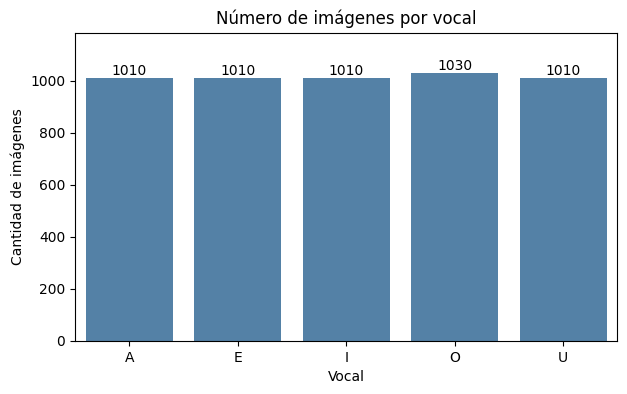

In [101]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=df_conteos, x="Vocal", y="Cantidad", color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Número de imágenes por vocal")
plt.xlabel("Vocal")
plt.ylabel("Cantidad de imágenes")
plt.ylim(0, df_conteos["Cantidad"].max() * 1.15)
plt.show()

Las clases están **balanceadas**: la diferencia entre la clase más grande (O, 1030) y las demás (1010) es de solo 20 imágenes, menos del 2 %. Esto evita que un modelo se incline hacia una clase en particular.

### Representación de las imágenes

Se muestra un ejemplo de cada vocal y se revisa cómo se representa una imagen internamente, es decir, la variable predictora X.

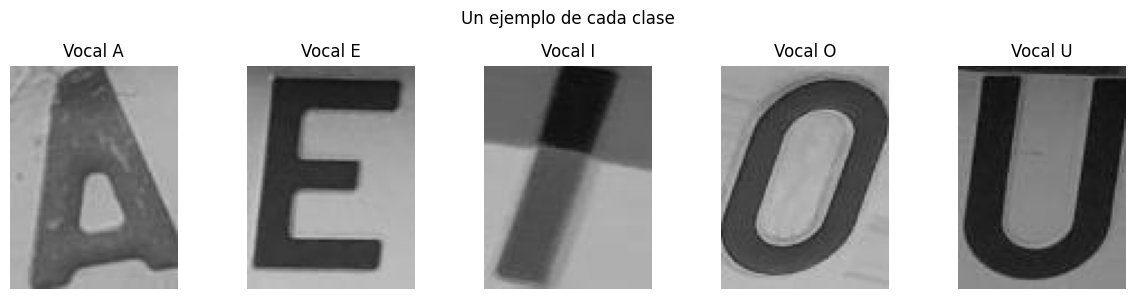

In [102]:
fig, axes = plt.subplots(1, len(carpetas), figsize=(12, 3))
for ax, carpeta in zip(axes, sorted(carpetas, key=lambda c: nombre_vocal[c])):
    primer_archivo = sorted(os.listdir(os.path.join(RUTA, carpeta)))[0]
    img = ski.io.imread(os.path.join(RUTA, carpeta, primer_archivo))
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Vocal {nombre_vocal[carpeta]}")
    ax.axis("off")
plt.suptitle("Un ejemplo de cada clase")
plt.tight_layout()
plt.show()

In [103]:
ruta_ejemplo = os.path.join(RUTA, "A", archivos_A[0])
img = ski.io.imread(ruta_ejemplo)

print("Archivo:", ruta_ejemplo)
print("Tipo de objeto:", type(img))
print("Forma (alto, ancho):", img.shape)
print("Número de dimensiones:", img.ndim)
print("Tipo de dato:", img.dtype)
print("Valor mínimo:", img.min(), "| Valor máximo:", img.max())
print("Número total de píxeles (variables de entrada):", img.size)
print("\nFragmento de la matriz (filas 45 a 49, columnas 30 a 37):")
print(img[45:50, 30:38])

Archivo: Only Vowels\A\aug100_19.jpg
Tipo de objeto: <class 'numpy.ndarray'>
Forma (alto, ancho): (100, 75)
Número de dimensiones: 2
Tipo de dato: uint8
Valor mínimo: 59 | Valor máximo: 194
Número total de píxeles (variables de entrada): 7500

Fragmento de la matriz (filas 45 a 49, columnas 30 a 37):
[[ 83  83  82  81  79  77  76  77]
 [ 82  80  79  77  74  72  71  73]
 [ 82  79  77  75  71  68  68  71]
 [ 79  80  74  70  69  87 114 122]
 [ 81  79  65  76  91 119 149 158]]


Cada imagen se carga como un arreglo de NumPy de forma **(100, 75)**: 100 píxeles de alto por 75 de ancho. Tiene **2 dimensiones**, lo que indica que está en escala de grises (un solo canal). Los valores son enteros de 8 bits (`uint8`) en el rango 0–255, donde 0 es negro y 255 blanco. En total, cada imagen aporta **7500 píxeles**, que son los valores numéricos con los que el modelo trabajará como variable predictora X.

# Inspección y exploración del Dataset

En esta sección se explora el conjunto de datos mediante herramientas gráficas (cuadrículas de imágenes, histogramas, diagramas de caja, gráficas de dispersión y mapas de calor), resúmenes estadísticos y matrices de correlación.

Como los datos son imágenes. Además de inspeccionarlas visualmente, se calculan **características estadísticas de cada imagen** (brillo, contraste, proporción de la letra, nitidez, etc.) para poder resumirlas y analizar su distribución y sus correlaciones.

### Carga de las imágenes y conversión a escala de grises

Se cargan todas las imágenes. Para garantizar que todas tengan un solo canal, se define la función `convertir_a_gris()`: si una imagen viene a color, la convierte a escala de grises con la fórmula del estándar ITU-R BT.601, que combina los canales rojo, verde y azul con pesos de 0,299, 0,587 y 0,114; si ya está en gris, la deja igual. Las imágenes se guardan en el arreglo **X** y sus etiquetas en **y**.

In [104]:
def convertir_a_gris(img):
    if img.ndim == 3:                         # imagen con varios canales (color)
        img = img[:, :, :3].astype(float)     # se descarta la transparencia si existe
        img = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]
        img = img.round().astype(np.uint8)    # de vuelta a enteros 0-255
    return img

imagenes, etiquetas = [], []
a_color = 0
for carpeta in carpetas:
    for archivo in sorted(os.listdir(os.path.join(RUTA, carpeta))):
        img = ski.io.imread(os.path.join(RUTA, carpeta, archivo))
        if img.ndim == 3:
            a_color += 1
        imagenes.append(convertir_a_gris(img))
        etiquetas.append(nombre_vocal[carpeta])

X = np.array(imagenes)
y = np.array(etiquetas)
vocales = sorted(np.unique(y))

print("Imágenes que venían a color y se convirtieron:", a_color)
print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

Imágenes que venían a color y se convirtieron: 0
Forma de X: (5070, 100, 75)
Forma de y: (5070,)


Se cargaron las 5070 imágenes. Ninguna venía a color, lo que confirma que todas ya estaban en escala de grises. **X** tiene forma (5070, 100, 75): 5070 imágenes de 100 × 75 píxeles. **y** contiene las 5070 etiquetas correspondientes.

### Revisión de imágenes repetidas y variantes

Se revisa si hay imágenes exactamente iguales en el conjunto de datos. Para esto se calcula una "huella" de cada imagen a partir de los valores de sus píxeles: dos imágenes con la misma huella son copias idénticas.

In [105]:
huellas = [hashlib.md5(img.tobytes()).hexdigest() for img in X]
repetidas = pd.Series(huellas).duplicated().sum()
print("Imágenes repetidas:", repetidas)

Imágenes repetidas: 0


No hay copias exactas: las 5070 imágenes son distintas entre sí. Sin embargo, que no haya copias exactas no significa que todas las imágenes sean independientes. Los nombres de los archivos tienen el formato `augNNNN_V.jpg`, donde `NNNN` es un número consecutivo y `V` indica el número de variante. A continuación se ordenan los archivos por su número para analizar ese patrón.

In [106]:
archivos = pd.DataFrame(
    [(carpeta, archivo) for carpeta in carpetas
     for archivo in sorted(os.listdir(os.path.join(RUTA, carpeta)))],
    columns=["carpeta", "archivo"],
)
archivos["numero"] = archivos["archivo"].str.split("_").str[0].str.replace("aug", "").astype(int)
archivos["variante"] = archivos["archivo"].str.split("_").str[1].str.replace(".jpg", "").astype(int)
archivos["vocal"] = y

# Cada vez que la variante vuelve a 0 empieza un grupo nuevo
orden = archivos.sort_values(["carpeta", "numero"])
orden["grupo"] = (orden["variante"] == 0).cumsum() - 1
archivos["grupo"] = orden["grupo"]
grupos = archivos["grupo"].to_numpy()

archivos.sort_values(["carpeta", "numero"]).head(12)

,carpeta,archivo,numero,variante,vocal,grupo
1010,0,aug8041_0.jpg,8041,0,O,0
1011,0,aug8042_1.jpg,8042,1,O,0
1012,0,aug8043_2.jpg,8043,2,O,0
1013,0,aug8044_3.jpg,8044,3,O,0
1014,0,aug8045_4.jpg,8045,4,O,0
1015,0,aug8046_5.jpg,8046,5,O,0
1016,0,aug8047_6.jpg,8047,6,O,0
1017,0,aug8048_7.jpg,8048,7,O,0
1018,0,aug8049_8.jpg,8049,8,O,0
1019,0,aug8050_9.jpg,8050,9,O,0


Al ordenar los archivos por su número, la variante aumenta de uno en uno (0, 1, 2, …) y luego vuelve a empezar en 0. Cada secuencia que empieza en la variante 0 se considera un **grupo**. Para comprobar qué representa cada grupo, se muestran las primeras 10 imágenes del primer grupo de cada vocal.

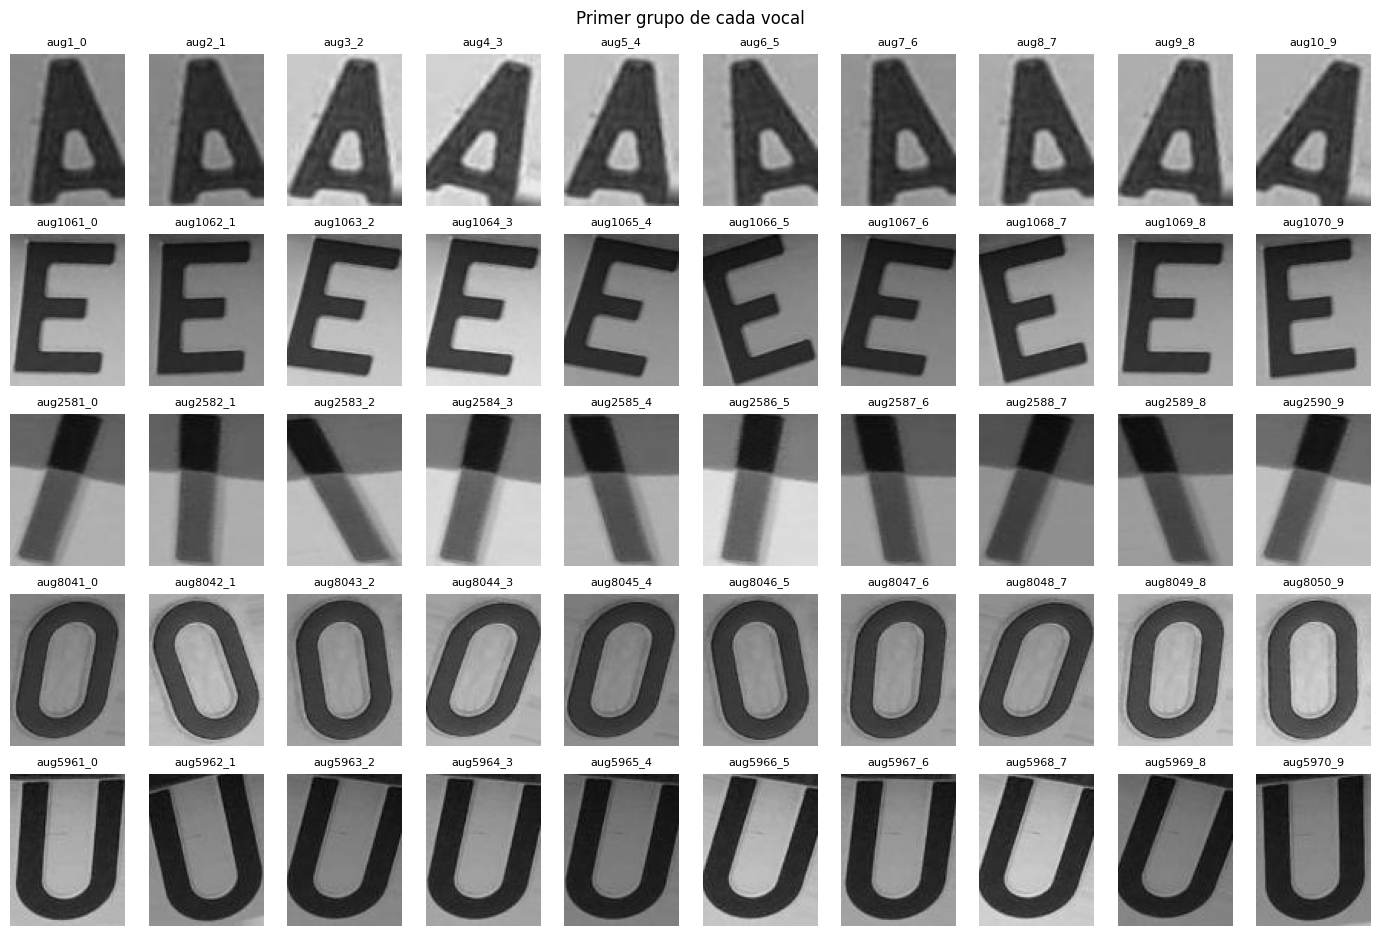

In [107]:
fig, axes = plt.subplots(len(vocales), 10, figsize=(14, 9.5))
for i, vocal in enumerate(vocales):
    primer_grupo = archivos[archivos["vocal"] == vocal]["grupo"].min()
    indices = archivos[archivos["grupo"] == primer_grupo].sort_values("numero").index[:10]
    for j, idx in enumerate(indices):
        axes[i, j].imshow(X[idx], cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_title(archivos.loc[idx, "archivo"].replace(".jpg", ""), fontsize=8)
        axes[i, j].axis("off")
fig.suptitle("Primer grupo de cada vocal")
plt.tight_layout()
plt.show()

Cada fila muestra la **misma fotografía** con distinta rotación y distinto brillo. Es decir, cada grupo está formado por variantes de una sola foto original, generadas mediante aumento de datos. Las variantes se parecen mucho, pero no son copias exactas, por eso no aparecieron como repetidas en la revisión anterior.

In [108]:
resumen_grupos = archivos.groupby("vocal").agg(
    Imágenes=("archivo", "count"),
    Grupos=("grupo", "nunique"),
)
print(resumen_grupos)
print("\nTotal de grupos:", archivos["grupo"].nunique())
print("Tamaño de los grupos (imágenes por grupo: cantidad de grupos):",
      archivos.groupby("grupo").size().value_counts().sort_index().to_dict())

       Imágenes  Grupos
vocal                  
A          1010      77
E          1010      90
I          1010      74
O          1030     102
U          1010     100

Total de grupos: 443
Tamaño de los grupos (imágenes por grupo: cantidad de grupos): {10: 379, 20: 64}


Las 5070 imágenes provienen de **443 fotografías originales**: 77 de la A, 90 de la E, 74 de la I, 102 de la O y 100 de la U. De esos grupos, 379 tienen 10 variantes y 64 tienen 20.

### Inspección visual de una muestra aleatoria

Se seleccionan 8 imágenes al azar de cada vocal y se muestran en una cuadrícula, una fila por vocal.

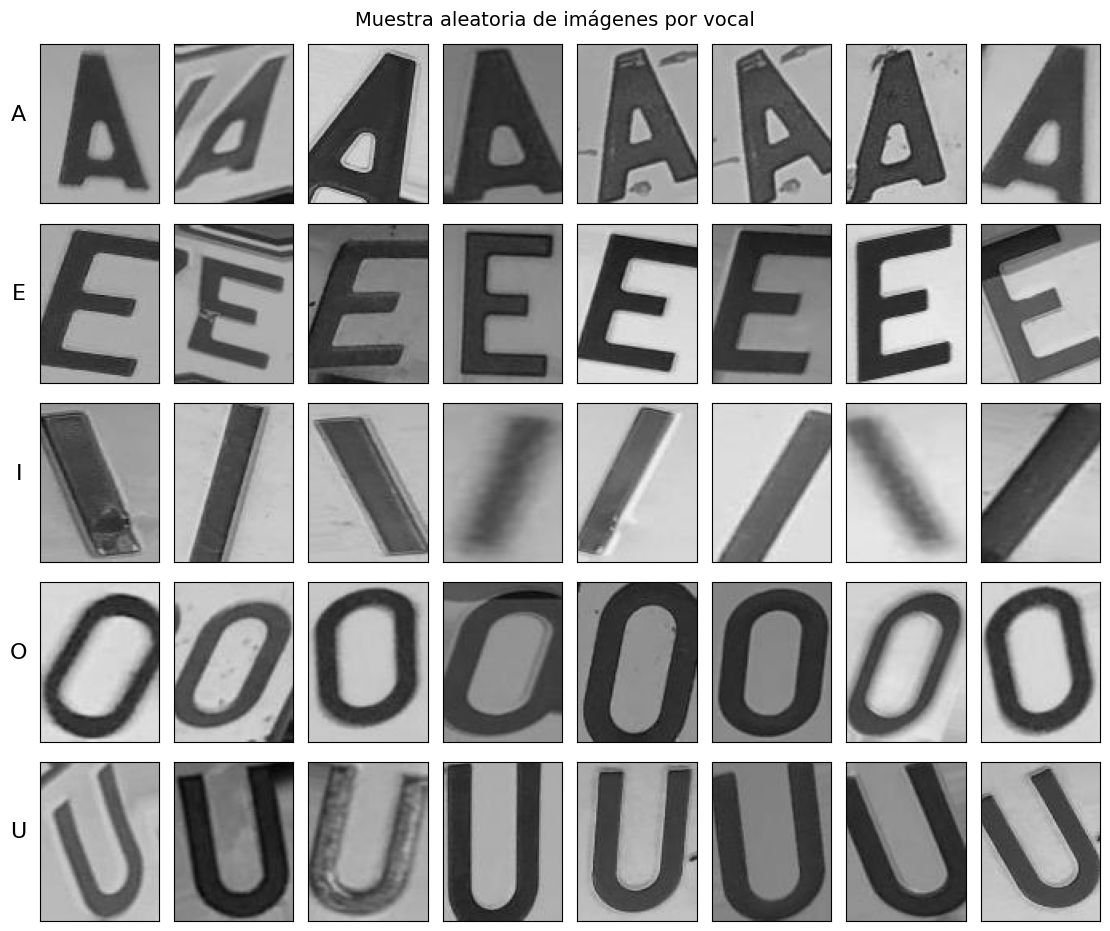

In [109]:
rng = np.random.default_rng(42)  # semilla para que la muestra sea reproducible
N = 8

fig, axes = plt.subplots(len(vocales), N, figsize=(N * 1.4, len(vocales) * 1.9))
for i, vocal in enumerate(vocales):
    indices = rng.choice(np.where(y == vocal)[0], size=N, replace=False)
    for j, idx in enumerate(indices):
        ax = axes[i, j]
        ax.imshow(X[idx], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([])
        ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(vocal, fontsize=16, rotation=0, labelpad=15)
fig.suptitle("Muestra aleatoria de imágenes por vocal", fontsize=14)
plt.tight_layout()
plt.show()

Al observar la muestra se identifican las siguientes variaciones:

*   **Tipo de letra:** aunque el dataset en Kaggle se llama *Handwriting*, las imágenes no parecen escritas a mano, sino fotografías de letras físicas (como las de placas o letreros) con una misma tipografía.
*   **Rotación:** muchas letras aparecen giradas o inclinadas, sobre todo la I y la O.
*   **Escala y recorte:** en algunas imágenes la letra llena el cuadro y queda cortada en los bordes; en otras se ve completa.
*   **Fondo e iluminación:** el fondo va de gris claro a gris oscuro y el contraste entre letra y fondo cambia de una imagen a otra.
*   **Ruido:** algunas imágenes presentan desenfoque, manchas o rayones.
*   La **I** es la vocal más difícil de reconocer a simple vista, porque es solo una barra y con rotación o recorte pierde su forma.

# Imagen promedio de cada vocal

Se calcula el promedio, píxel a píxel, de todas las imágenes de cada vocal. Esto muestra la forma "típica" de cada clase.

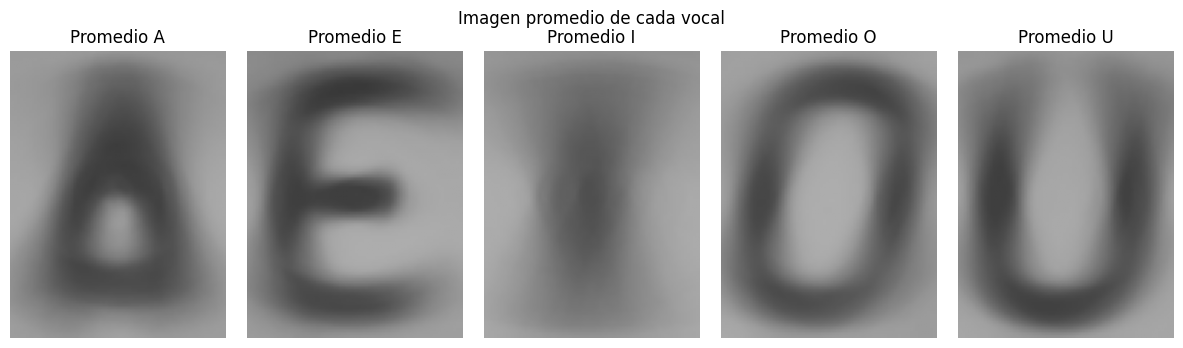

In [110]:
promedios = {}
fig, axes = plt.subplots(1, len(vocales), figsize=(12, 3.5))
for ax, vocal in zip(axes, vocales):
    promedios[vocal] = X[y == vocal].mean(axis=0)
    ax.imshow(promedios[vocal], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Promedio {vocal}")
    ax.axis("off")
fig.suptitle("Imagen promedio de cada vocal")
plt.tight_layout()
plt.show()

A pesar de las rotaciones y variaciones, la imagen promedio de cada vocal conserva una forma reconocible: se distinguen claramente la A, la E, la O y la U. Esto indica que la posición de los píxeles oscuros contiene información útil para clasificar. La **I** es la excepción: su promedio es una mancha difusa, porque la barra aparece en distintas posiciones e inclinaciones. Esto confirma que será la clase más difícil.

También se observa que la O y la U tienen promedios parecidos (ambas tienen trazos verticales a los lados y una curva en la parte inferior), lo que anticipa posibles confusiones entre ellas.

### Distribución de intensidades de los píxeles

Se construye un histograma con los valores de todos los píxeles de cada vocal (de 0 = negro a 255 = blanco).

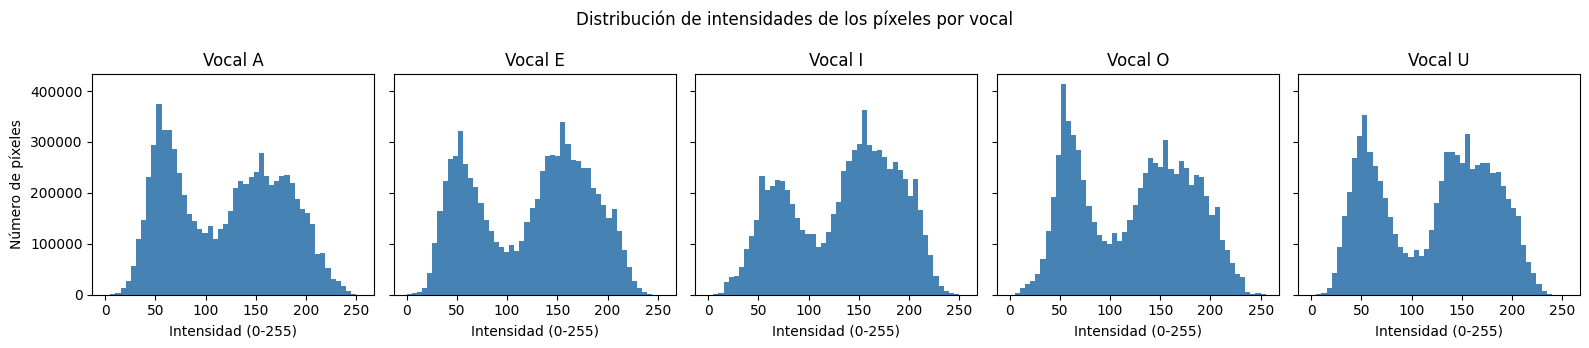

In [111]:
fig, axes = plt.subplots(1, len(vocales), figsize=(16, 3.5), sharey=True)
for ax, vocal in zip(axes, vocales):
    ax.hist(X[y == vocal].ravel(), bins=50, range=(0, 255), color="steelblue")
    ax.set_title(f"Vocal {vocal}")
    ax.set_xlabel("Intensidad (0-255)")
axes[0].set_ylabel("Número de píxeles")
fig.suptitle("Distribución de intensidades de los píxeles por vocal")
plt.tight_layout()
plt.show()

Todos los histogramas tienen dos picos:

*   Un pico en valores bajos (alrededor de 50–60), que corresponde a los píxeles oscuros de la **letra**.
*   Un pico en valores medios-altos (alrededor de 150–170), que corresponde al **fondo**, más claro.

Esta separación indica que la letra y el fondo se pueden distinguir bien por su intensidad. En la **I**, el pico oscuro es más bajo que en las demás vocales porque la letra ocupa una menor parte de la imagen. En la **A** y la **O** ese pico es el más alto, porque su trazo cubre más área.

### Extracción de características estadísticas por imagen

Para resumir cada imagen con pocos valores, se calculan las siguientes características:

| Característica | Descripción |
|---|---|
| `brillo` | Intensidad promedio de la imagen. |
| `contraste` | Desviación estándar de las intensidades . |
| `pixel_mas_oscuro` | Intensidad más oscura de la imagen. |
| `pixel_mas_claro` | Intensidad más clara de la imagen. |
| `area_letra` | Fracción de píxeles que pertenecen a la letra.
| `definicion_bordes` | Mide qué tan definidos son los bordes. Valores bajos indican una imagen borrosa. |

In [112]:
def caracteristicas(img):
    umbral = ski.filters.threshold_otsu(img)
    return {
        "brillo": img.mean(),
        "contraste": img.std(),
        "pixel_mas_oscuro": img.min(),
        "pixel_mas_claro": img.max(),
        "area_letra": (img < umbral).mean(),
        "definicion_bordes": ski.filters.laplace(ski.util.img_as_float(img)).var(),
    }

df = pd.DataFrame([caracteristicas(img) for img in X])
df["vocal"] = y
columnas = ["brillo", "contraste", "pixel_mas_oscuro", "pixel_mas_claro", "area_letra", "definicion_bordes"]

df.sample(10, random_state=42)

,brillo,contraste,pixel_mas_oscuro,pixel_mas_claro,area_letra,definicion_bordes,vocal
2021,153.374933,58.776712,52,217,0.430000,0.005093,A
1840,113.561333,52.638955,25,181,0.432533,0.010758,A
3316,100.652933,41.452041,16,161,0.389333,0.001013,I
1893,87.122800,44.317722,20,150,0.480000,0.003524,A
1988,113.468533,69.492973,9,221,0.515333,0.020419,A
3819,122.549867,38.257939,48,164,0.347600,0.000863,I
2764,144.989067,65.240904,42,217,0.410267,0.003292,E
3630,108.776933,53.283025,17,187,0.488533,0.000882,I
497,111.610933,51.111638,19,184,0.444133,0.004632,O
1032,150.812800,42.814186,63,213,0.448133,0.004536,A


### Resumen estadístico

Se obtiene el resumen estadístico de las características para todo el conjunto de datos y el promedio de cada característica por vocal.

In [113]:
df[columnas].describe().round(3)

,brillo,contraste,pixel_mas_oscuro,pixel_mas_claro,area_letra,definicion_bordes
count,5070.000,5070.000,5070.000,5070.000,5070.000,5070.000
mean,124.780,50.002,27.802,192.217,0.407,0.006
std,23.031,9.926,16.911,28.230,0.082,0.005
min,56.092,22.880,0.000,119.000,0.204,0.000
25%,107.410,42.613,15.000,169.000,0.360,0.002
50%,123.887,49.665,25.000,193.000,0.403,0.004
75%,140.550,56.982,38.000,215.000,0.445,0.008
max,198.193,82.411,123.000,255.000,0.762,0.034


In [114]:
df.groupby("vocal")[columnas].mean().round(3)

,brillo,contraste,pixel_mas_oscuro,pixel_mas_claro,area_letra,definicion_bordes
vocal,,,,,,
A,120.187,50.026,30.128,190.016,0.449,0.005
E,123.462,51.580,23.381,190.402,0.410,0.007
I,134.174,47.362,28.749,194.326,0.354,0.004
O,123.972,49.792,29.321,193.104,0.423,0.006
U,122.119,51.256,27.402,193.221,0.396,0.007


*   **Brillo (`brillo`):** el brillo promedio es 124,8, con valores entre 56,1 y 198,2. Hay imágenes mucho más oscuras que otras, es decir, la iluminación varía bastante.
*   **Contraste (`contraste`):** el contraste promedio es 50,0, con valores entre 22,9 y 82,4. En algunas imágenes la letra se distingue poco del fondo.
*   **Tonos extremos (`pixel_mas_oscuro` y `pixel_mas_claro`):** en promedio, el píxel más oscuro de cada imagen tiene un valor de 27,8 y el más claro de 192,2. Solo 96 de las 5070 imágenes (1,9 %) llegan al negro total (0) y solo 10 (0,2 %) al blanco total (255).
*   **Área de la letra (`area_letra`):** en promedio, la letra ocupa el 40,7 % de la imagen, con valores entre 20,4 % y 76,2 %. Al revisar las imágenes con los valores más altos, se observa que son imágenes de la A donde una parte del fondo también es oscura, y ese fondo se cuenta por error como letra. Por eso esta medida no es exacta cuando el fondo tiene zonas oscuras.
*   **Definición de bordes (`definicion_bordes`):** el valor promedio es 0,0057 y la mediana 0,0043, con valores entre 0,0001 y 0,0344. Que el promedio sea mayor que la mediana indica que solo unas pocas imágenes tienen bordes muy marcados. Al ordenar las 5070 imágenes de menor a mayor definición de bordes, las 8 primeras (las más borrosas) son todas de la vocal I.

Por vocal, la **I** se diferencia de las demás: es la de mayor brillo promedio (134,2), la de menor área de letra (35,4 %) y la de bordes menos marcados (0,0038). Esto tiene sentido porque la I es una sola barra delgada, así que ocupa poco espacio en la imagen. La **A** es la de mayor área de letra (44,9 %). Las demás vocales tienen valores muy parecidos entre sí.

### Histogramas de las características

Se grafica la distribución de cada característica para todo el conjunto de datos.

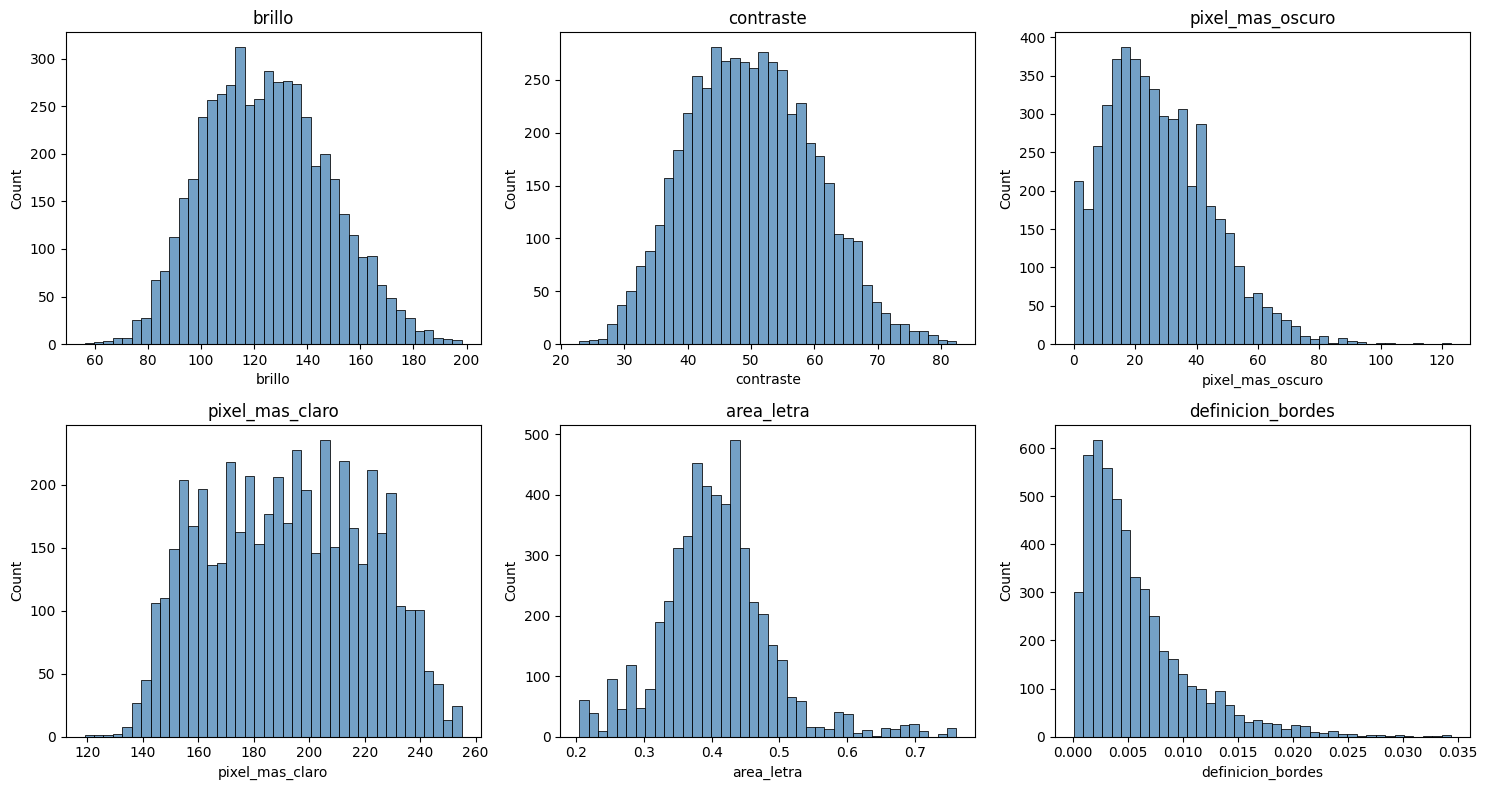

In [115]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), columnas):
    sns.histplot(df[col], bins=40, ax=ax, color="steelblue")
    ax.set_title(f"{col}")
plt.tight_layout()
plt.show()

### Diagramas de caja por vocal

Los diagramas de caja permiten comparar la distribución de cada característica entre las vocales e identificar valores atípicos.

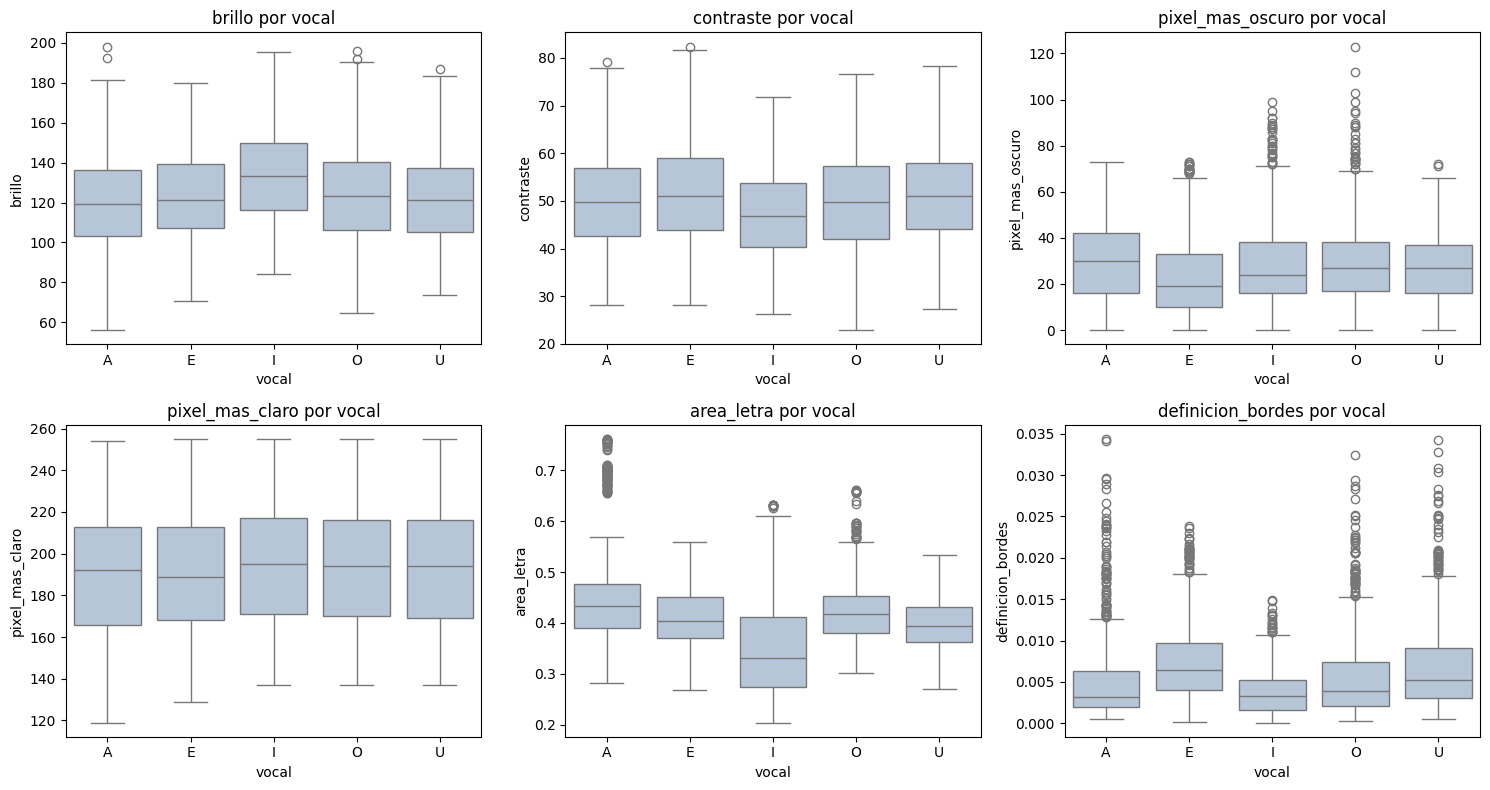

In [116]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), columnas):
    sns.boxplot(data=df, x="vocal", y=col, order=vocales, ax=ax, color="lightsteelblue")
    ax.set_title(f"{col} por vocal")
plt.tight_layout()
plt.show()

Para precisar lo que muestran las gráficas, se cuentan los valores atípicos de cada característica por vocal, con la misma regla que usa el diagrama de cajas. También se calcula la asimetría de cada característica: 0 significa que los valores se reparten parejo a ambos lados del centro, y un valor alto, que hay una cola larga hacia un lado.

In [117]:
conteo = {}
for col in columnas:
    conteo[col] = {}
    for vocal, grupo in df.groupby("vocal")[col]:
        q1, q3 = grupo.quantile([0.25, 0.75])
        altura = q3 - q1
        conteo[col][vocal] = ((grupo < q1 - 1.5 * altura) | (grupo > q3 + 1.5 * altura)).sum()

tabla_atipicos = pd.DataFrame(conteo).T
tabla_atipicos["Total"] = tabla_atipicos.sum(axis=1)
tabla_atipicos["Asimetría"] = df[columnas].skew().round(2)
tabla_atipicos.sort_values("Total", ascending=False)

,A,E,I,O,U,Total,Asimetría
definicion_bordes,73,36,21,58,44,232,1.75
area_letra,90,0,10,34,0,134,0.75
pixel_mas_oscuro,0,19,29,30,2,80,0.74
brillo,2,0,0,2,1,5,0.23
contraste,1,1,0,0,0,2,0.19
pixel_mas_claro,0,0,0,0,0,0,0.01


*   La **I** es la vocal que más se diferencia: tiene las imágenes más claras y la letra que ocupa menos espacio. La **A** es la que ocupa más espacio.
*   `definicion_bordes` es la característica con más valores atípicos (232), sobre todo en la A y la O. Esto pasa porque la mayoría de las imágenes tiene valores bajos y solo unas pocas, las de letras grandes y bien enfocadas, tienen valores muy altos.
*   Los valores atípicos no se eliminan, porque son fotos reales con otra iluminación, otro enfoque u otro fondo, no errores.
*   Las cajas de las cinco vocales se superponen bastante, así que estas características por sí solas no permiten diferenciar las vocales. Lo que realmente las distingue es **la forma de la letra**.

### Matriz de correlación entre características

La correlación indica si dos características cambian juntas. Toma valores entre -1 y 1:

*   Cerca de **1**: cuando una aumenta, la otra también aumenta.
*   Cerca de **-1**: cuando una aumenta, la otra disminuye.
*   Cerca de **0**: no hay una relación clara entre ellas.

Se utiliza la correlación de **Spearman**, porque no exige que la relación entre las variables sea una línea recta: solo mide si, cuando una aumenta, la otra tiende a aumentar (o a disminuir). Es la más adecuada aquí porque, como se vio en la sección 2.8, varias características no tienen forma de campana.

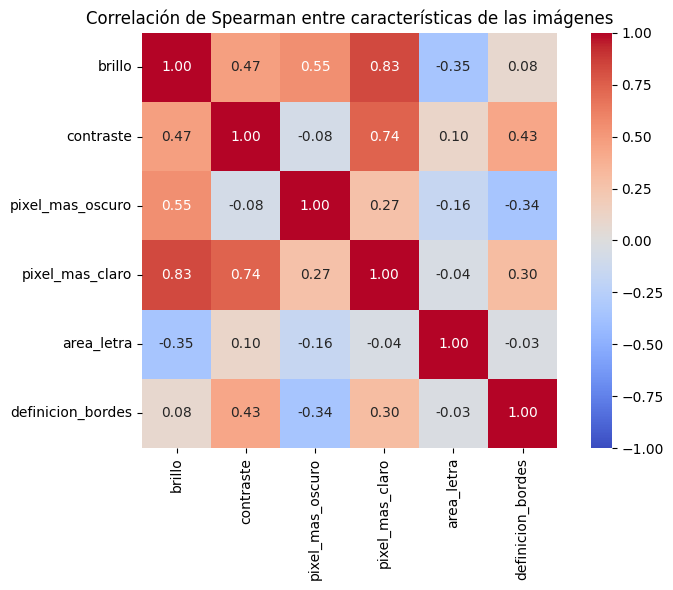

In [118]:
corr = df[columnas].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlación de Spearman entre características de las imágenes")
plt.tight_layout()
plt.show()

*   **`brillo` y `pixel_mas_claro` (0,83):** es la correlación más alta. Las imágenes más claras en general también tienen un fondo más claro, que es donde está el píxel más claro.
*   **`contraste` y `pixel_mas_claro` (0,74):** cuanto más claro es el fondo, más se diferencia de la letra oscura.
*   **`brillo` y `pixel_mas_oscuro` (0,55):** en las imágenes más iluminadas, incluso la letra se ve menos oscura.
*   **`brillo` y `contraste` (0,47)** y **`contraste` y `definicion_bordes` (0,43):** relaciones moderadas. Las imágenes donde la letra se diferencia más del fondo tienden a tener bordes más marcados.
*   **`brillo` y `area_letra` (-0,35):** correlación negativa. Cuanto más espacio ocupa la letra oscura, más oscura es la imagen en general.
*   **`pixel_mas_oscuro` y `definicion_bordes` (-0,34):** en las imágenes donde la letra no llega a verse muy oscura, los bordes tienden a ser menos marcados.
*   `area_letra` tiene una correlación baja con las demás características (excepto con `brillo`), así que aporta información distinta.

#### Revisión del par más correlacionado

Una correlación alta no significa necesariamente que las dos características midan lo mismo y que una de ellas sobre. Para revisarlo, se grafica la relación entre `brillo` y `pixel_mas_claro`.

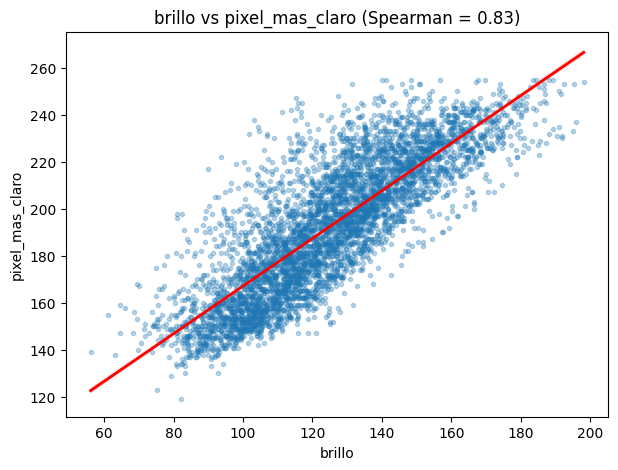

In [119]:
rho = corr.loc["brillo", "pixel_mas_claro"]

plt.figure(figsize=(7, 5))
sns.regplot(data=df, x="brillo", y="pixel_mas_claro", marker=".",
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red", "linewidth": 2})
plt.title(f"brillo vs pixel_mas_claro (Spearman = {rho:.2f})")
plt.show()

La gráfica muestra una tendencia clara: cuando aumenta el brillo, también aumenta el píxel más claro. Sin embargo, los puntos están bastante dispersos alrededor de la línea.

Esto ocurre porque miden cosas distintas: `pixel_mas_claro` depende de un solo punto (normalmente en el fondo), mientras que `brillo` depende de toda la imagen, incluido cuánto espacio ocupa la letra oscura. Por lo tanto, aunque están relacionadas, **no son redundantes**, y no se elimina ninguna de las dos en esta etapa.

# Preparación de los datos

En esta sección se describen las estrategias utilizadas para preparar los datos de acuerdo con las necesidades del trabajo. Cada decisión se justifica con lo encontrado durante la inspección del conjunto de datos.


### Conversión de la variable objetivo

La variable objetivo **y** contiene las vocales como texto (A, E, I, O, U), tomadas del nombre de la carpeta de cada imagen. Se convierte a números para que, al igual que las imágenes, quede representada con valores numéricos. Se usa la codificación de enteros (*Integer Encoding*) con `LabelEncoder`, que asigna un número entero a cada clase en orden alfabético. Estos números solo identifican cada vocal; no indican ningún orden entre ellas.

In [120]:
le = LabelEncoder()
y_num = le.fit_transform(y)

pd.DataFrame({
    "Vocal": le.classes_,
    "Número asignado": le.transform(le.classes_),
    "Imágenes": np.bincount(y_num),
})

,Vocal,Número asignado,Imágenes
0,A,0,1010
1,E,1,1010
2,I,2,1010
3,O,3,1030
4,U,4,1010


Cada vocal quedó representada por un número: A = 0, E = 1, I = 2, O = 3 y U = 4.

### Redimensionamiento de las imágenes

Cada imagen tiene 100 × 75 = 7500 píxeles. Se reduce su tamaño para disminuir el número de variables por imagen. Para elegir el tamaño, se comparan varios tamaños que conservan la proporción original (4:3), mostrando una imagen al azar de cada vocal.

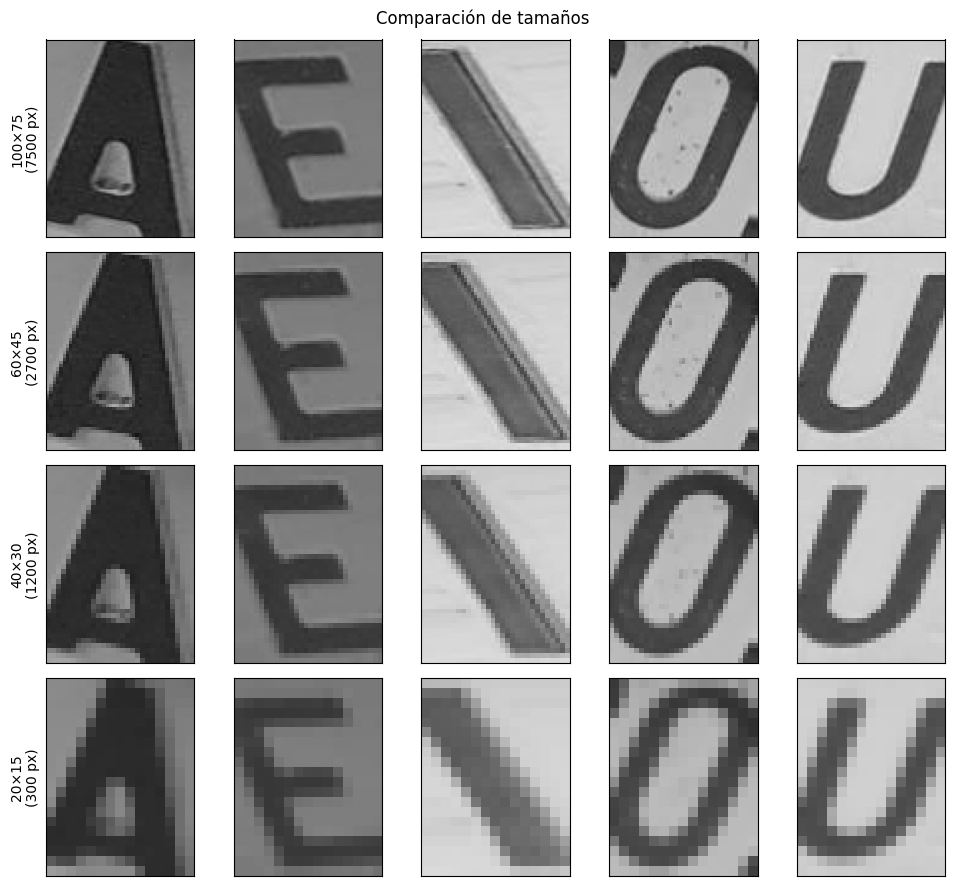

In [121]:
tamanos = [(100, 75), (60, 45), (40, 30), (20, 15)]
rng = np.random.default_rng(0)
ejemplos = [rng.choice(np.where(y == v)[0]) for v in vocales]

fig, axes = plt.subplots(len(tamanos), len(vocales), figsize=(10, 9))
for i, (alto, ancho) in enumerate(tamanos):
    for j, idx in enumerate(ejemplos):
        img = ski.transform.resize(X[idx], (alto, ancho), anti_aliasing=True,
                                   preserve_range=True).round().astype(np.uint8)
        axes[i, j].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])
        if j == 0:
            axes[i, j].set_ylabel(f"{alto}×{ancho}\n({alto * ancho} px)")
fig.suptitle("Comparación de tamaños")
plt.tight_layout()
plt.show()

*   En **60 × 45** las imágenes se ven prácticamente iguales a las originales.
*   En **40 × 30** la forma de cada vocal se conserva claramente: se distinguen el hueco de la A, los tres trazos de la E y la curva de la U.
*   En **20 × 15** las imágenes se ven pixeladas y se pierden detalles; por ejemplo, el hueco de la A casi desaparece.

Se elige el tamaño **40 × 30**, que conserva la forma de las letras y reduce cada imagen de 7500 a 1200 píxeles.

In [122]:
ALTO, ANCHO = 40, 30

# anti_aliasing suaviza la imagen antes de reducirla; preserve_range mantiene la escala 0-255
X_red = np.array([
    ski.transform.resize(img, (ALTO, ANCHO), anti_aliasing=True,
                         preserve_range=True).round().astype(np.uint8)
    for img in X
])

print("Forma original:", X.shape)
print("Forma redimensionada:", X_red.shape)
print("Tipo de dato:", X_red.dtype, "| Rango:", X_red.min(), "-", X_red.max())
print("Píxeles por imagen:", ALTO * ANCHO)

Forma original: (5070, 100, 75)
Forma redimensionada: (5070, 40, 30)
Tipo de dato: uint8 | Rango: 1 - 252
Píxeles por imagen: 1200


Las 5070 imágenes quedaron con forma 40 × 30 (40 píxeles de alto por 30 de ancho), es decir, 1200 píxeles por imagen. Los valores siguen siendo enteros (`uint8`) y quedaron entre 1 y 252.

### Vectorización de las imágenes

Los métodos de scikit-learn reciben los datos como una tabla, donde cada fila es un ejemplo y cada columna una variable. Por eso, cada imagen de 40 × 30 se convierte en una fila de 1200 valores, colocando las filas de píxeles de la imagen una después de otra.

In [123]:
X_vec = X_red.reshape(len(X_red), -1)

print("Forma antes:", X_red.shape)
print("Forma después:", X_vec.shape)
print("Primeros 10 píxeles de la primera fila de la imagen:", X_red[0, 0, :10])
print("Primeros 10 valores del vector:                      ", X_vec[0, :10])
print("¿Se puede recuperar la imagen original?:", np.array_equal(X_vec[0].reshape(ALTO, ANCHO), X_red[0]))

Forma antes: (5070, 40, 30)
Forma después: (5070, 1200)
Primeros 10 píxeles de la primera fila de la imagen: [161 161 161 162 162 162 162 162 161 159]
Primeros 10 valores del vector:                       [161 161 161 162 162 162 162 162 161 159]
¿Se puede recuperar la imagen original?: True


El conjunto quedó como una tabla de **5070 filas** (una por imagen) y **1200 columnas** (una por píxel). Los primeros valores del vector coinciden con la primera fila de píxeles de la imagen, y al reorganizar el vector se recupera la imagen original, lo que confirma que la vectorización no pierde información.

### División en conjuntos de entrenamiento y prueba

Se separa un conjunto de prueba, que no se usa durante la preparación de los datos. La división se hace en este punto porque el escalamiento y la reducción de dimensionalidad deben ajustarse solo con los datos de entrenamiento: si se ajustaran con todos los datos, la información del conjunto de prueba influiría en la preparación (*data leakage*).

En la inspección se encontró que las imágenes provienen de 443 fotografías, cada una con 10 o 20 variantes. Se revisa cuántas fotografías quedarían repartidas entre entrenamiento y prueba si la división se hiciera al azar.

In [124]:
# División al azar, solo para comparar
idx_train_azar, idx_test_azar = train_test_split(
    np.arange(len(X_vec)), test_size=0.20, stratify=y_num, random_state=42
)

fotos_train = set(grupos[idx_train_azar])
fotos_test = set(grupos[idx_test_azar])
compartidas = fotos_train & fotos_test

print("Fotografías con variantes en entrenamiento y en prueba:", len(compartidas), "de", len(set(grupos)))

Fotografías con variantes en entrenamiento y en prueba: 399 de 443


Con una división al azar, **399 de las 443 fotografías** tendrían variantes tanto en entrenamiento como en prueba. En ese caso, el modelo se evaluaría con imágenes casi iguales a las que vio al entrenar, lo que también es *data leakage* y haría que los resultados en prueba fueran más altos de lo real.

Por eso, la división se hace **por grupos**, con `StratifiedGroupKFold`: se reparten los grupos en 5 partes, de modo que todas las variantes de una misma fotografía queden en la misma parte, y tratando de mantener la proporción de cada vocal. Una de las 5 partes (aproximadamente el 20 % de las imágenes) se usa como conjunto de prueba, y las otras 4 como entrenamiento.

In [125]:
division = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_train, idx_test = next(division.split(X_vec, y_num, groups=grupos))

X_train, X_test = X_vec[idx_train], X_vec[idx_test]
y_train, y_test = y_num[idx_train], y_num[idx_test]
grupos_train = grupos[idx_train]   # se usan en la validación cruzada del punto 4

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Grupos compartidos entre entrenamiento y prueba:",
      len(set(grupos_train) & set(grupos[idx_test])))

tabla_division = pd.DataFrame({
    "Vocal": le.classes_,
    "Entrenamiento": np.bincount(y_train),
    "Prueba": np.bincount(y_test),
    "Fotografías en prueba": [len(set(grupos[idx_test][y_test == k])) for k in range(len(le.classes_))],
})
tabla_division["% en prueba"] = (tabla_division["Prueba"] /
                                 (tabla_division["Entrenamiento"] + tabla_division["Prueba"]) * 100).round(1)
tabla_division

Entrenamiento: (4060, 1200)
Prueba: (1010, 1200)
Grupos compartidos entre entrenamiento y prueba: 0


,Vocal,Entrenamiento,Prueba,Fotografías en prueba,% en prueba
0,A,810,200,15,19.8
1,E,810,200,18,19.8
2,I,810,200,14,19.8
3,O,820,210,21,20.4
4,U,810,200,20,19.8


### Escalamiento de los píxeles

Los píxeles toman valores enteros entre 0 y 255. Como se vio en clase, no escalar los datos afecta el funcionamiento del algoritmo del descenso del gradiente. Por eso, los píxeles se llevan al rango de 0 a 1 con la fórmula del escalamiento Min-Max:

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

usando como mínimo y máximo los límites de cualquier píxel, 0 y 255, con lo que la fórmula queda $x' = x / 255$. Se usan estos límites fijos en lugar de la función `MinMaxScaler`, porque esta calcula un mínimo y un máximo distintos para cada posición de píxel, lo que haría que un mismo tono de gris quedara con valores diferentes según su posición en la imagen. Como se divide entre un valor fijo, la misma operación se aplica igual a entrenamiento y prueba, sin aprender nada de los datos.

In [126]:
X_train_esc = X_train / 255.0
X_test_esc = X_test / 255.0

print(f"Entrenamiento: mínimo {X_train_esc.min():.4f}, máximo {X_train_esc.max():.4f}")
print(f"Prueba:        mínimo {X_test_esc.min():.4f}, máximo {X_test_esc.max():.4f}")

Entrenamiento: mínimo 0.0039, máximo 0.9882
Prueba:        mínimo 0.0196, máximo 0.9608


### Reducción de dimensionalidad con PCA

Cada imagen sigue teniendo 1200 variables. El PCA (Análisis de Componentes Principales) crea nuevas variables, llamadas **componentes principales**, que combinan los píxeles originales y están ordenadas según cuánta de la variación de los datos conservan. Así se puede representar cada imagen con menos valores, perdiendo la menor información posible.

El PCA se ajusta solo con los datos de entrenamiento. Primero se calcula con todos los componentes para ver cuánta variación conservan a medida que se agregan.

In [127]:
pca_completo = PCA()
pca_completo.fit(X_train_esc)
varianza_acumulada = np.cumsum(pca_completo.explained_variance_ratio_)

for k in [1, 10, 50, 100, 200, 300, 500, 1200]:
    print(f"Con {k:4d} componentes se conserva el {varianza_acumulada[k - 1] * 100:.2f} % de la variación")

Con    1 componentes se conserva el 21.26 % de la variación
Con   10 componentes se conserva el 72.17 % de la variación
Con   50 componentes se conserva el 92.85 % de la variación
Con  100 componentes se conserva el 96.26 % de la variación
Con  200 componentes se conserva el 98.48 % de la variación
Con  300 componentes se conserva el 99.21 % de la variación
Con  500 componentes se conserva el 99.75 % de la variación
Con 1200 componentes se conserva el 100.00 % de la variación


Para elegir el número de componentes se sigue el criterio del ejemplo de PCA de la clase: conservar los componentes necesarios para explicar un alto porcentaje de la variación de los datos, en este caso el **95 %**. Se indica directamente con `n_components=0.95`, y el PCA calcula cuántos componentes necesita para lograrlo. Se ajusta con el conjunto de entrenamiento y luego se aplica al de prueba.

Componentes seleccionados: 76
Variación conservada: 95.05 %
Entrenamiento: (4060, 76)
Prueba: (1010, 76)


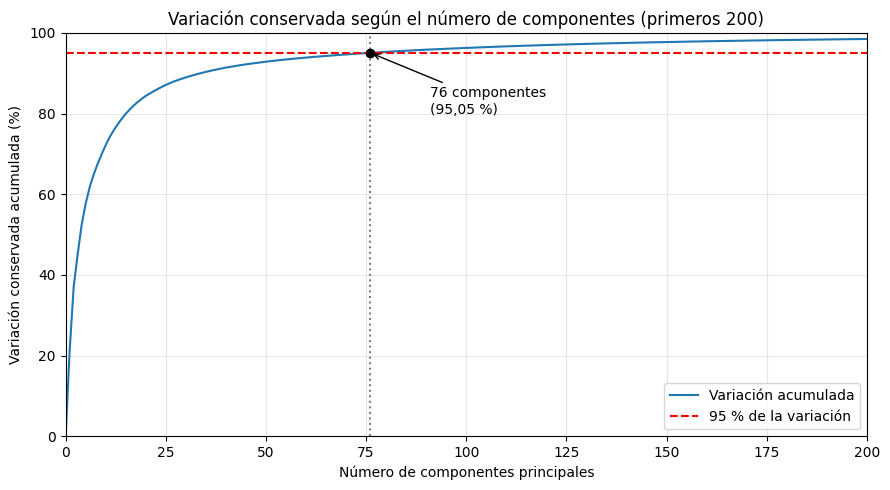

In [128]:
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_esc)
X_test_pca = pca.transform(X_test_esc)

print("Componentes seleccionados:", pca.n_components_)
print(f"Variación conservada: {pca.explained_variance_ratio_.sum() * 100:.2f} %")
print("Entrenamiento:", X_train_pca.shape)
print("Prueba:", X_test_pca.shape)

k = pca.n_components_
LIMITE = 200
componentes = np.arange(0, LIMITE + 1)                              # desde 0 componentes
curva = np.concatenate(([0], varianza_acumulada[:LIMITE])) * 100   # con 0 componentes: 0 %
porcentaje_k = varianza_acumulada[k - 1] * 100

plt.figure(figsize=(9, 5))
plt.plot(componentes, curva, label="Variación acumulada")
plt.axhline(95, color="red", linestyle="--", label="95 % de la variación")
plt.axvline(k, color="gray", linestyle=":")
plt.plot(k, porcentaje_k, "o", color="black")
plt.annotate(f"{k} componentes\n({porcentaje_k:.2f} %)".replace(".", ","),
             xy=(k, porcentaje_k), xytext=(k + 15, 80),
             arrowprops=dict(arrowstyle="->"))
plt.xlim(0, LIMITE)
plt.ylim(0, 100)
plt.xlabel("Número de componentes principales")
plt.ylabel("Variación conservada acumulada (%)")
plt.title(f"Variación conservada según el número de componentes (primeros {LIMITE})")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Sin componentes no se conserva ninguna variación (0 %); el primer componente, por sí solo, conserva el 21,26 %, por lo que la curva sube bruscamente al inicio. Con 10 componentes se conserva el 72,17 %, y con 50, el 92,85 %. Para conservar el 95 % se necesitan **76 componentes** (95,05 %), como marca el punto negro en la gráfica.

La gráfica muestra solo los primeros 200 componentes porque a partir de ahí la curva es prácticamente plana: con 200 componentes ya se conserva el 98,48 % y con los 1200 el 100 %, según la tabla anterior. En la gráfica se ve que la curva sube rápidamente con los primeros componentes y luego se aplana: después de los 76 componentes, agregar más aporta muy poca variación adicional.

Así, cada imagen pasa de 1200 variables a **76** (93,7 % menos). Que tan pocos componentes conserven casi toda la variación indica que gran parte de la información de los píxeles era repetida. El conjunto de entrenamiento queda con forma (4060, 76) y el de prueba con forma (1010, 76).

### Resumen de las estrategias de preparación

| Estrategia | Descripción |
|---|---|
| Conversión a escala de grises | Se aplicó al cargar las imágenes con la fórmula BT.601, para garantizar un solo canal. Ninguna imagen venía a color. |
| Conversión de la variable objetivo | Las vocales se convirtieron a números de 0 a 4 con codificación de enteros. |
| Redimensionamiento | Las imágenes pasaron de 100 × 75 a 40 × 30, de 7500 a 1200 píxeles, conservando la forma de las letras. |
| Vectorización (flattening) | Cada imagen se aplanó en una fila de 1200 valores. |
| División en entrenamiento y prueba | Se hizo por grupos, para que todas las variantes de una misma fotografía queden en un solo conjunto: 4060 imágenes para entrenamiento y 1010 para prueba, con el mismo balance de clases. |
| Escalamiento | Los píxeles se llevaron al rango de 0 a 1 con la fórmula Min-Max, usando los límites fijos 0 y 255. |
| Reducción de dimensionalidad | Con PCA, cada imagen pasó de 1200 a 76 variables, conservando el 95 % de la varianza. |

Al terminar la preparación, los datos quedan así: **X_train_pca** (4060 × 76) y **y_train** como conjunto de entrenamiento, y **X_test_pca** (1010 × 76) y **y_test** como conjunto de prueba.

# **REVISAR DESDE AQUI OJO**

# Ajuste de hiperparámetros y evaluación de los modelos

Para cada método se sigue el mismo procedimiento:

1.  **Modelo base:** se entrena con los valores por defecto de sus hiperparámetros y se evalúa en entrenamiento y prueba, como punto de referencia.
2.  **Ajuste de hiperparámetros con `GridSearchCV`:** se prueban todas las combinaciones de valores indicadas y cada una se evalúa con validación cruzada de 5 partes, usando solo el conjunto de entrenamiento. En cada ronda se entrena con 4 partes y se valida con la restante. La combinación con el mayor *accuracy* promedio se usa para entrenar el modelo final con todo el conjunto de entrenamiento.
3.  **Evaluación:** el modelo final se evalúa en entrenamiento y en prueba. Al final del punto se comparan todos los modelos.

Como las variantes de una misma fotografía deben quedar juntas, la validación cruzada se hace con `StratifiedGroupKFold`, que reparte los grupos en las 5 partes manteniendo la proporción de cada vocal.

La métrica utilizada es el *accuracy* (proporción de imágenes clasificadas correctamente), adecuada porque las clases están balanceadas. Comparar el *accuracy* de entrenamiento con el de validación y prueba permite identificar sobreajuste: si el modelo es mucho mejor en entrenamiento, está memorizando esos datos.

### . Experimentos para ajustar los hiperparámetros de los modelos

En este punto se entrenan los métodos vistos en clase para clasificar las vocales: regresión multivariada, árboles de decisión, Random Forest y redes neuronales (MLP y DNN). Todos reciben los mismos datos, que son el resultado de la preparación: `X_train_pca` y `X_test_pca`, con 76 componentes principales por imagen, y sus etiquetas `y_train` y `y_test`.

Las siguientes librerías contienen los modelos y las funciones de evaluación que se utilizan en los experimentos.

### 4.1 Forma de realizar los experimentos

Con cada método se siguen los mismos tres pasos:

1. **Modelo base.** Se entrena el modelo con una configuración inicial, sin buscar todavía sus mejores hiperparámetros, y se evalúa. En la regresión se parte del modelo sin regularización y en los demás métodos de los valores que la librería trae por defecto. Este resultado es el punto de comparación para saber si el ajuste de hiperparámetros mejora o no al modelo.
2. **Ajuste de hiperparámetros con `GridSearchCV`.** Se define una lista de valores para cada hiperparámetro y `GridSearchCV` entrena el modelo con todas las combinaciones posibles. Cada combinación se evalúa con validación cruzada de 5 partes usando únicamente el conjunto de entrenamiento: el modelo se entrena con 4 partes y se valida con la parte restante, y esto se repite 5 veces cambiando la parte de validación. La calificación de la combinación es el promedio de los 5 resultados.
3. **Evaluación del modelo ajustado.** La combinación con el mayor promedio en validación se evalúa sobre el conjunto de entrenamiento y sobre el conjunto de prueba, que no participa en ningún momento del ajuste.

La métrica con la que se comparan las combinaciones es el accuracy (la proporción de imágenes clasificadas correctamente), porque las cinco vocales tienen casi la misma cantidad de imágenes.

**Validación cruzada por grupos.** En el conjunto de datos hay imágenes que son variantes de una misma fotografía. Si las variantes de una fotografía quedaran repartidas entre las partes de entrenamiento y de validación, el modelo se validaría con imágenes casi iguales a las que ya vio y el accuracy de validación sería más alto de lo real. Por eso la validación cruzada se hace con `StratifiedGroupKFold`, igual que la división entre entrenamiento y prueba: todas las variantes de una fotografía quedan en la misma parte y cada parte conserva la proporción de vocales. Este objeto se le entrega a `GridSearchCV` en el parámetro `cv`.

In [129]:
validacion = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

for parte, (_, idx_val) in enumerate(validacion.split(X_train_pca, y_train, groups=grupos_train), start=1):
    print(f"Parte {parte}: {len(idx_val)} imágenes de validación")

Parte 1: 820 imágenes de validación
Parte 2: 810 imágenes de validación
Parte 3: 810 imágenes de validación
Parte 4: 810 imágenes de validación
Parte 5: 810 imágenes de validación


Las 4060 imágenes de entrenamiento quedan repartidas en 5 partes de tamaño casi igual: una de 820 imágenes y cuatro de 810. En cada vuelta de la validación cruzada el modelo se entrena con 3240 o 3250 imágenes y se valida con las restantes.

Para mostrar los resultados de todos los modelos de la misma forma se define la función `evaluar_modelo`. Recibe las etiquetas reales y las predicciones de un modelo y muestra:

- El **accuracy**.
- El **reporte de clasificación**, que para cada vocal indica la *precision* (de las imágenes que el modelo clasificó como esa vocal, qué proporción lo era realmente), el *recall* (de las imágenes que realmente son de esa vocal, qué proporción encontró el modelo) y el *F1-score*, que resume las dos anteriores en un solo valor.
- La **matriz de confusión**, donde cada fila es la vocal real y cada columna la vocal que predijo el modelo. Los aciertos quedan en la diagonal y cualquier número por fuera de ella es un error.

Cada modelo se evalúa dos veces: sobre el conjunto de entrenamiento y sobre el conjunto de prueba. Comparar los dos resultados permite ver si hay sobreajuste, es decir, si el modelo acierta mucho más en las imágenes con las que fue entrenado que en imágenes nuevas.

In [130]:
def evaluar_modelo(nombre_modelo, tipo_evaluacion, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)

    print(f"Modelo: {nombre_modelo}")
    print(f"Accuracy : {accuracy:.4f}")

    print(f"\nReporte de clasificación para: - {tipo_evaluacion}")
    print(classification_report(y_true, y_pred, target_names=le.classes_, digits=4))

    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=le.classes_,
                                            cmap="Blues", values_format="d")
    plt.title(f"Matriz de confusión - {nombre_modelo} ({tipo_evaluacion})")
    plt.show()

### 4.2 Regresión multivariada (Softmax)

La regresión multivariada para clasificación se implementa con `LogisticRegression`. Como el problema tiene cinco clases, el modelo utiliza la función Softmax: calcula un valor para cada vocal a partir de una combinación lineal de las 76 variables de la imagen y convierte esos cinco valores en probabilidades que suman 1. La imagen se asigna a la vocal con la mayor probabilidad.

Primero se entrenan tres modelos: sin regularización, con regularización L2 (Ridge) y con regularización L1 (Lasso). Después se ajustan los hiperparámetros con `GridSearchCV`.

#### 4.2.1 Regresión Softmax sin regularización

En `LogisticRegression` el parámetro `C` controla la fuerza de la regularización: los valores pequeños aplican más regularización y los valores grandes aplican menos. Con `C=np.inf` (infinito) el modelo se entrena sin regularización. Este primer modelo es el punto de comparación para ver el efecto de la regularización L2 y L1.

In [131]:
reg_sin = LogisticRegression(C=np.inf, solver="newton-cg", max_iter=1000)
reg_sin.fit(X_train_pca, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",inf
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'newton-cg'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

Modelo: Regresión Softmax
Accuracy : 1.0000

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       810
           E     1.0000    1.0000    1.0000       810
           I     1.0000    1.0000    1.0000       810
           O     1.0000    1.0000    1.0000       820
           U     1.0000    1.0000    1.0000       810

    accuracy                         1.0000      4060
   macro avg     1.0000    1.0000    1.0000      4060
weighted avg     1.0000    1.0000    1.0000      4060



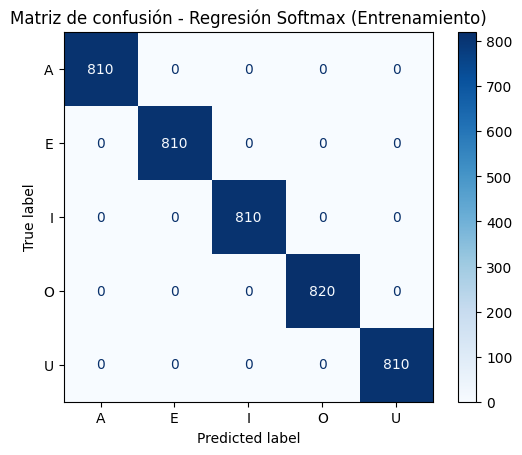

Modelo: Regresión Softmax
Accuracy : 0.9782

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       200
           E     1.0000    0.9400    0.9691       200
           I     0.9302    1.0000    0.9639       200
           O     0.9670    0.9762    0.9716       210
           U     1.0000    0.9750    0.9873       200

    accuracy                         0.9782      1010
   macro avg     0.9794    0.9782    0.9784      1010
weighted avg     0.9793    0.9782    0.9783      1010



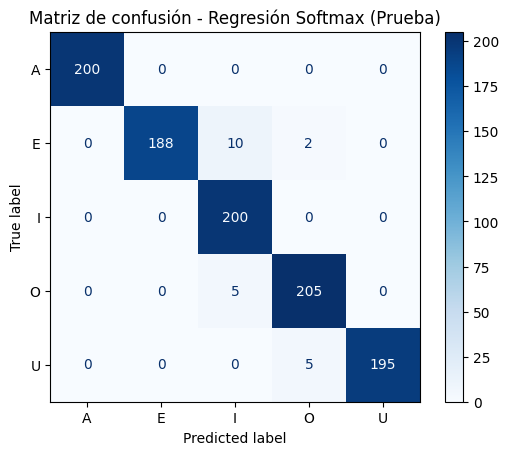

In [132]:
reg_sin_pred_train = reg_sin.predict(X_train_pca)
reg_sin_pred_test = reg_sin.predict(X_test_pca)

evaluar_modelo("Regresión Softmax", "Entrenamiento", y_train, reg_sin_pred_train)
evaluar_modelo("Regresión Softmax", "Prueba", y_test, reg_sin_pred_test)

Sin regularización, el modelo clasifica correctamente el 100 % de las imágenes de entrenamiento y el 97,82 % de las de prueba, es decir, 988 de 1010. La diferencia entre los dos conjuntos es de 2,18 puntos.

La matriz de confusión de prueba muestra que los 22 errores se concentran en dos vocales: en 15 de ellos el modelo clasificó como I una imagen que no lo era (10 de la E y 5 de la O) y en los otros 7 clasificó como O una imagen de otra vocal (5 de la U y 2 de la E). Esto se refleja en el reporte de clasificación: la I tiene recall de 1,0000, porque todas las I fueron encontradas, pero la precision más baja (0,9302), y la E tiene el recall más bajo (0,9400).

#### 4.2.2 Regresión Softmax con regularización L2 (Ridge)

`LogisticRegression` usa por defecto la regularización L2, que penaliza los coeficientes grandes para obtener un modelo más simple. Se entrena con `C=1.0`, que es el valor por defecto de la librería.

In [133]:
reg_ridge = LogisticRegression(C=1.0, solver="newton-cg", max_iter=5000)
reg_ridge.fit(X_train_pca, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'newton-cg'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

Modelo: Regresión Softmax L2 (Ridge)
Accuracy : 0.9995

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       810
           E     1.0000    1.0000    1.0000       810
           I     1.0000    1.0000    1.0000       810
           O     0.9976    1.0000    0.9988       820
           U     1.0000    0.9975    0.9988       810

    accuracy                         0.9995      4060
   macro avg     0.9995    0.9995    0.9995      4060
weighted avg     0.9995    0.9995    0.9995      4060



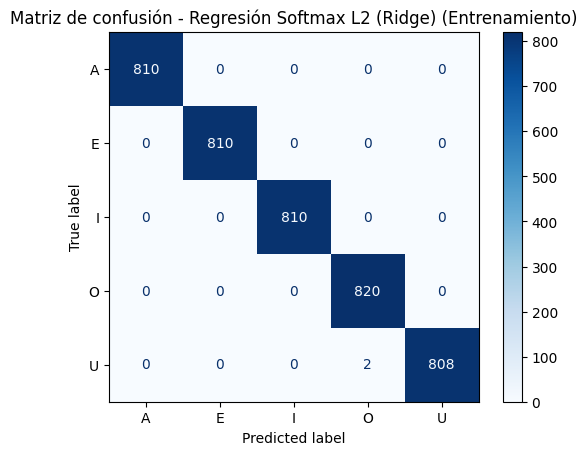

Modelo: Regresión Softmax L2 (Ridge)
Accuracy : 0.9832

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     1.0000    0.9950    0.9975       200
           E     1.0000    0.9500    0.9744       200
           I     0.9302    1.0000    0.9639       200
           O     0.9904    0.9810    0.9856       210
           U     1.0000    0.9900    0.9950       200

    accuracy                         0.9832      1010
   macro avg     0.9841    0.9832    0.9833      1010
weighted avg     0.9842    0.9832    0.9833      1010



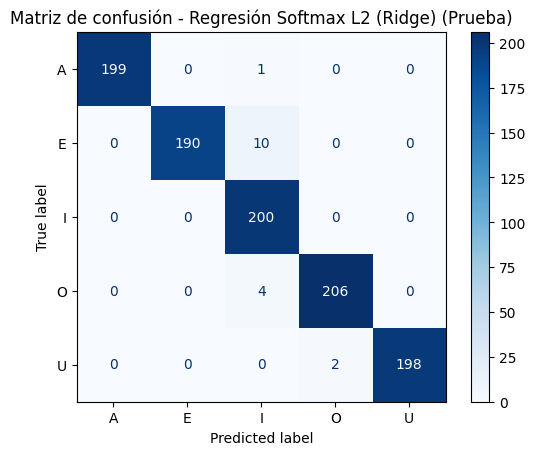

In [134]:
reg_ridge_pred_train = reg_ridge.predict(X_train_pca)
reg_ridge_pred_test = reg_ridge.predict(X_test_pca)

evaluar_modelo("Regresión Softmax L2 (Ridge)", "Entrenamiento", y_train, reg_ridge_pred_train)
evaluar_modelo("Regresión Softmax L2 (Ridge)", "Prueba", y_test, reg_ridge_pred_test)

Con la regularización L2 el accuracy de entrenamiento baja de 100 % a 99,95 % (2 imágenes de la U clasificadas como O) y el de prueba sube de 97,82 % a 98,32 %, es decir, 993 de 1010. Los errores en prueba pasan de 22 a 17 y la diferencia entre entrenamiento y prueba se reduce de 2,18 a 1,63 puntos. El modelo aprende un poco menos las imágenes de entrenamiento y clasifica un poco mejor las imágenes nuevas, que es el efecto que se busca con la regularización.

El tipo de error se mantiene: 15 de los 17 errores son imágenes clasificadas como I (10 de la E, 4 de la O y 1 de la A) y los otros 2 son imágenes de la U clasificadas como O.

#### 4.2.3 Regresión Softmax con regularización L1 (Lasso)

La regularización L1 penaliza la suma de los valores absolutos de los coeficientes. A diferencia de L2, puede llevar algunos coeficientes exactamente a cero, lo que equivale a que el modelo deje de usar esas variables.

El tipo de regularización se indica con el parámetro `l1_ratio`: con 1 es L1 y con 0 es L2. Se utiliza `solver="saga"`, que es el método de optimización que permite la regularización L1 en clasificación con varias clases, y `C=0.1`.

In [135]:
reg_lasso = LogisticRegression(l1_ratio=1, solver="saga", C=0.1, max_iter=10000, random_state=42)
reg_lasso.fit(X_train_pca, y_train)

print("Coeficientes del modelo:", reg_lasso.coef_.size)
print("Coeficientes iguales a cero:", (reg_lasso.coef_ == 0).sum())

Coeficientes del modelo: 380
Coeficientes iguales a cero: 304


Modelo: Regresión Softmax L1 (Lasso)
Accuracy : 0.9901

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     0.9975    0.9877    0.9926       810
           E     1.0000    0.9951    0.9975       810
           I     0.9805    0.9914    0.9859       810
           O     0.9866    0.9902    0.9884       820
           U     0.9864    0.9864    0.9864       810

    accuracy                         0.9901      4060
   macro avg     0.9902    0.9901    0.9902      4060
weighted avg     0.9902    0.9901    0.9902      4060



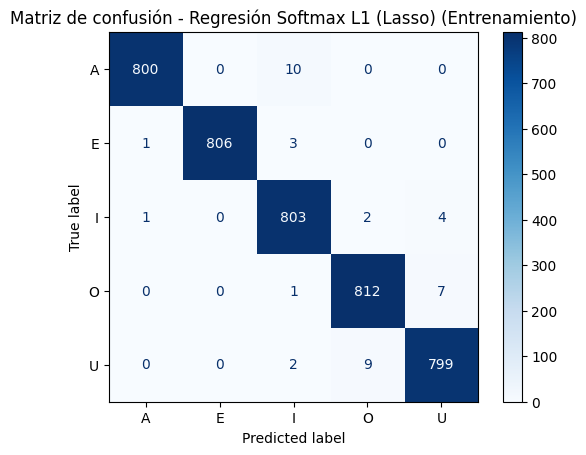

Modelo: Regresión Softmax L1 (Lasso)
Accuracy : 0.9723

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     1.0000    0.9300    0.9637       200
           E     1.0000    0.9700    0.9848       200
           I     0.9009    1.0000    0.9479       200
           O     0.9855    0.9714    0.9784       210
           U     0.9851    0.9900    0.9875       200

    accuracy                         0.9723      1010
   macro avg     0.9743    0.9723    0.9725      1010
weighted avg     0.9744    0.9723    0.9725      1010



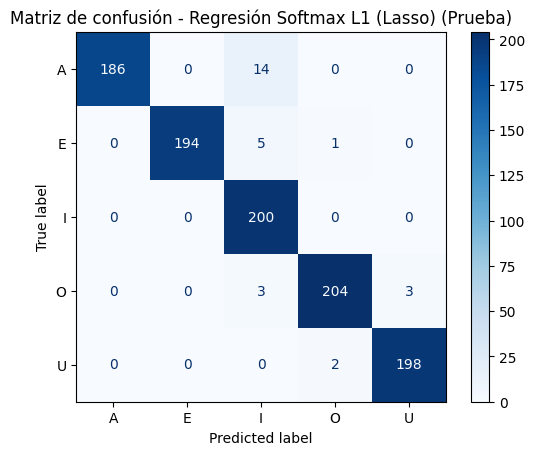

In [136]:
reg_lasso_pred_train = reg_lasso.predict(X_train_pca)
reg_lasso_pred_test = reg_lasso.predict(X_test_pca)

evaluar_modelo("Regresión Softmax L1 (Lasso)", "Entrenamiento", y_train, reg_lasso_pred_train)
evaluar_modelo("Regresión Softmax L1 (Lasso)", "Prueba", y_test, reg_lasso_pred_test)

El modelo tiene 380 coeficientes (76 variables por cada una de las 5 vocales) y la regularización L1 con `C=0.1` dejó 304 de ellos en cero, es decir, el modelo clasifica usando solo 76 coeficientes.

Con esta configuración el accuracy es de 99,01 % en entrenamiento y de 97,23 % en prueba (982 de 1010), los valores más bajos de los tres modelos. De los 28 errores en prueba, 22 son imágenes clasificadas como I, y la mayoría ya no viene de la E sino de la A: 14 imágenes de la A, 5 de la E y 3 de la O. Por eso la A tiene el recall más bajo (0,9300) y la I la precision más baja (0,9009).

Con los valores usados en estos tres modelos, la regularización L2 fue la de mejor resultado en prueba (98,32 %), seguida del modelo sin regularización (97,82 %) y de la regularización L1 (97,23 %).

#### 4.2.4 Ajuste de hiperparámetros con GridSearchCV

**Regresión Softmax sin regularización**

Como este modelo no tiene regularización, el hiperparámetro que se ajusta es `tol`, la tolerancia con la que el entrenamiento decide detenerse: mientras más pequeño es el valor, más se acerca el entrenamiento al mínimo de la función de pérdida antes de parar. Se prueban tres valores, entre ellos el que trae la librería por defecto (0,0001).

In [137]:
parametros_reg_sin = {"tol": [1e-3, 1e-4, 1e-5]}

grid_reg_sin = GridSearchCV(LogisticRegression(C=np.inf, solver="newton-cg", max_iter=2000), parametros_reg_sin,
                            scoring="accuracy", cv=validacion, return_train_score=True, n_jobs=-1)
grid_reg_sin.fit(X_train_pca, y_train, groups=grupos_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...r='newton-cg')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'tol': [0.001, 0.0001, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificsc

In [138]:
resultados_reg_sin = pd.DataFrame(grid_reg_sin.cv_results_).rename(columns={"mean_test_score": "mean_val_score",
                                                                            "std_test_score": "std_val_score"})

display(resultados_reg_sin[["param_tol", "mean_train_score", "mean_val_score", "std_val_score"]].round(4))

,param_tol,mean_train_score,mean_val_score,std_val_score
0,0.0010,1.0,0.9695,0.0158
1,0.0001,1.0,0.9665,0.0191
2,0.0000,1.0,0.9663,0.0184


In [139]:
print("Mejores hiperparámetros:", grid_reg_sin.best_params_)
print("Mejor accuracy promedio en validación:", round(grid_reg_sin.best_score_, 4))

reg_sin_grid = grid_reg_sin.best_estimator_

Mejores hiperparámetros: {'tol': 0.001}
Mejor accuracy promedio en validación: 0.9695


Modelo: Regresión Softmax GridSearch
Accuracy : 1.0000

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       810
           E     1.0000    1.0000    1.0000       810
           I     1.0000    1.0000    1.0000       810
           O     1.0000    1.0000    1.0000       820
           U     1.0000    1.0000    1.0000       810

    accuracy                         1.0000      4060
   macro avg     1.0000    1.0000    1.0000      4060
weighted avg     1.0000    1.0000    1.0000      4060



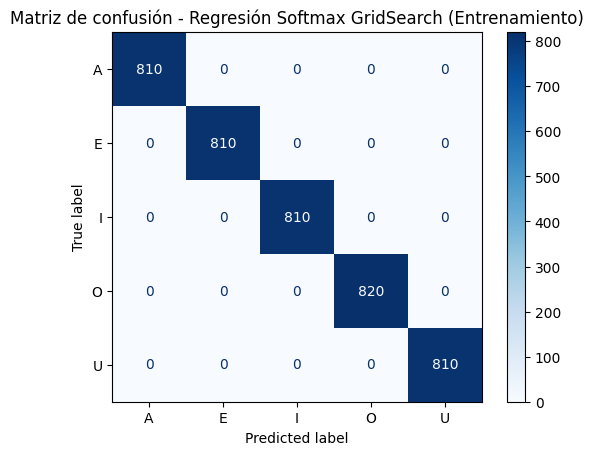

Modelo: Regresión Softmax GridSearch
Accuracy : 0.9792

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       200
           E     1.0000    0.9400    0.9691       200
           I     0.9346    1.0000    0.9662       200
           O     0.9671    0.9810    0.9740       210
           U     1.0000    0.9750    0.9873       200

    accuracy                         0.9792      1010
   macro avg     0.9803    0.9792    0.9793      1010
weighted avg     0.9802    0.9792    0.9793      1010



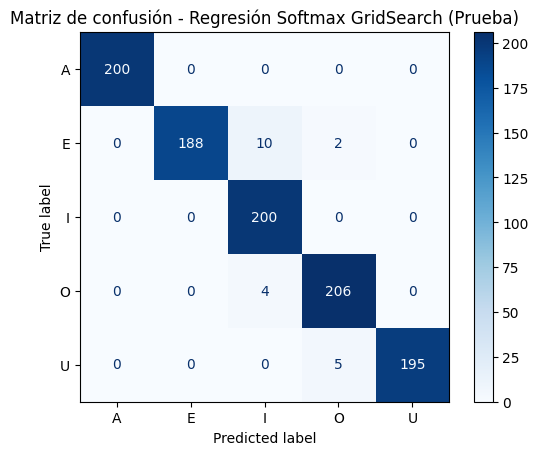

In [140]:
reg_sin_grid_pred_train = reg_sin_grid.predict(X_train_pca)
reg_sin_grid_pred_test = reg_sin_grid.predict(X_test_pca)

evaluar_modelo("Regresión Softmax GridSearch", "Entrenamiento", y_train, reg_sin_grid_pred_train)
evaluar_modelo("Regresión Softmax GridSearch", "Prueba", y_test, reg_sin_grid_pred_test)

En la tabla, `mean_train_score` es el accuracy promedio en las partes con las que se entrenó, `mean_val_score` es el accuracy promedio en las partes de validación y `std_val_score` es la desviación estándar entre las 5 partes de validación.

Los tres valores de `tol` alcanzan 100 % de accuracy en entrenamiento y quedan muy cerca en validación: 96,95 % con `tol=0.001`, 96,65 % con el valor por defecto y 96,63 % con `tol=0.00001`. `GridSearchCV` seleccionó `tol=0.001`, que es el valor con el que el entrenamiento se detiene antes.

El modelo seleccionado obtiene 100 % en entrenamiento y 97,92 % en prueba (989 de 1010). Frente al modelo sin regularización entrenado al inicio (97,82 %), la diferencia es de una sola imagen: 21 errores en lugar de 22. El ajuste de `tol` prácticamente no cambió el resultado.

**Regresión Softmax con regularización**

Ridge (L2) y Lasso (L1) se implementan con la misma función `LogisticRegression`, así que el tipo de regularización se incluye como un hiperparámetro más de la búsqueda. Los hiperparámetros que se ajustan son:

- `l1_ratio`: el tipo de regularización, 1 para L1 (Lasso) y 0 para L2 (Ridge).
- `C`: la fuerza de la regularización, con cinco valores de 0,01 (mucha regularización) a 100 (poca regularización).

En total son 10 combinaciones y 50 entrenamientos. Se utiliza `solver="saga"` porque admite los dos tipos de regularización.

In [141]:
parametros_reg = {"l1_ratio": [1, 0],
                  "C": [0.01, 0.1, 1, 10, 100]}

grid_reg = GridSearchCV(LogisticRegression(solver="saga", max_iter=5000, random_state=42), parametros_reg,
                        scoring="accuracy", cv=validacion, return_train_score=True, n_jobs=-1)
grid_reg.fit(X_train_pca, y_train, groups=grupos_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...solver='saga')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 0.1, ...], 'l1_ratio': [1, 0]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t t

In [142]:
resultados_reg = pd.DataFrame(grid_reg.cv_results_).rename(columns={"mean_test_score": "mean_val_score",
                                                                    "std_test_score": "std_val_score"})

display(resultados_reg[["param_l1_ratio", "param_C", "mean_train_score", "mean_val_score", "std_val_score"]].round(4))

,param_l1_ratio,param_C,mean_train_score,mean_val_score,std_val_score
0,1,0.01,0.9073,0.8854,0.0264
1,0,0.01,0.9847,0.9586,0.0160
2,1,0.10,0.9880,0.9531,0.0229
3,0,0.10,0.9975,0.9689,0.0168
4,1,1.00,0.9994,0.9601,0.0178
5,0,1.00,0.9999,0.9690,0.0146
6,1,10.00,1.0000,0.9635,0.0186
7,0,10.00,1.0000,0.9682,0.0170
8,1,100.00,1.0000,0.9663,0.0185
9,0,100.00,1.0000,0.9660,0.0189


In [143]:
print("Mejores hiperparámetros:", grid_reg.best_params_)
print("Mejor accuracy promedio en validación:", round(grid_reg.best_score_, 4))

reg_grid = grid_reg.best_estimator_

Mejores hiperparámetros: {'C': 1, 'l1_ratio': 0}
Mejor accuracy promedio en validación: 0.969


Modelo: Regresión Softmax con regularización GridSearch
Accuracy : 0.9995

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       810
           E     1.0000    1.0000    1.0000       810
           I     1.0000    1.0000    1.0000       810
           O     0.9976    1.0000    0.9988       820
           U     1.0000    0.9975    0.9988       810

    accuracy                         0.9995      4060
   macro avg     0.9995    0.9995    0.9995      4060
weighted avg     0.9995    0.9995    0.9995      4060



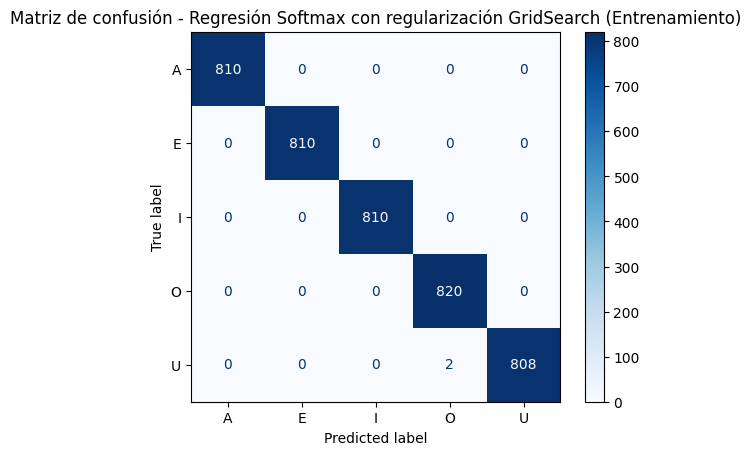

Modelo: Regresión Softmax con regularización GridSearch
Accuracy : 0.9812

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     1.0000    0.9900    0.9950       200
           E     1.0000    0.9500    0.9744       200
           I     0.9259    1.0000    0.9615       200
           O     0.9856    0.9810    0.9833       210
           U     1.0000    0.9850    0.9924       200

    accuracy                         0.9812      1010
   macro avg     0.9823    0.9812    0.9813      1010
weighted avg     0.9823    0.9812    0.9813      1010



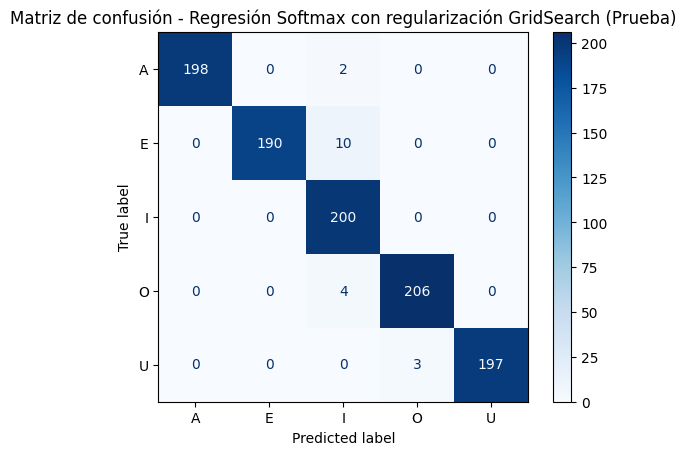

In [144]:
reg_grid_pred_train = reg_grid.predict(X_train_pca)
reg_grid_pred_test = reg_grid.predict(X_test_pca)

evaluar_modelo("Regresión Softmax con regularización GridSearch", "Entrenamiento", y_train, reg_grid_pred_train)
evaluar_modelo("Regresión Softmax con regularización GridSearch", "Prueba", y_test, reg_grid_pred_test)

De la tabla se observa lo siguiente:

- La mejor combinación es la regularización L2 con `C=1`, con 96,90 % de accuracy promedio en validación.
- La regularización L2 supera a la L1 en todos los valores de `C`, excepto en `C=100`, donde quedan prácticamente iguales (96,60 % y 96,63 %).
- Con mucha regularización el modelo queda con subajuste: con L1 y `C=0.01` el accuracy es de 90,73 % en entrenamiento y 88,54 % en validación, los valores más bajos de la tabla. A medida que `C` aumenta, L1 mejora hasta 96,63 %.
- Con L2 el resultado casi no cambia entre `C=0.1`, `C=1` y `C=10` (96,89 %, 96,90 % y 96,82 %). Desde `C=10` el accuracy de entrenamiento llega a 100 % en los dos tipos de regularización, pero el de validación no mejora.

El modelo seleccionado obtiene 99,95 % en entrenamiento y 98,12 % en prueba (991 de 1010, con 19 errores). Su configuración (L2 con `C=1`) es la misma del modelo Ridge entrenado antes, que obtuvo 98,32 % en prueba con 17 errores; lo que cambia entre los dos es el método de optimización (`saga` en lugar de `newton-cg`), y la diferencia es de 2 imágenes.

**Segunda búsqueda**

Como la mejor combinación fue `C=1`, se hace una segunda búsqueda con valores de `C` más cercanos a ese, entre los dos valores vecinos de la primera búsqueda (0,1 y 10).

In [145]:
parametros_reg2 = {"l1_ratio": [1, 0],
                   "C": [0.2, 0.5, 2, 5]}

grid_reg2 = GridSearchCV(LogisticRegression(solver="saga", max_iter=5000, random_state=42), parametros_reg2,
                         scoring="accuracy", cv=validacion, return_train_score=True, n_jobs=-1)
grid_reg2.fit(X_train_pca, y_train, groups=grupos_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...solver='saga')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.2, 0.5, ...], 'l1_ratio': [1, 0]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t th

In [146]:
resultados_reg2 = pd.DataFrame(grid_reg2.cv_results_).rename(columns={"mean_test_score": "mean_val_score",
                                                                      "std_test_score": "std_val_score"})

display(resultados_reg2[["param_l1_ratio", "param_C", "mean_train_score", "mean_val_score", "std_val_score"]].round(4))

,param_l1_ratio,param_C,mean_train_score,mean_val_score,std_val_score
0,1,0.2,0.9954,0.9564,0.0226
1,0,0.2,0.9987,0.9689,0.0153
2,1,0.5,0.9987,0.9601,0.0202
3,0,0.5,0.9995,0.9694,0.0148
4,1,2.0,0.9999,0.9613,0.0167
5,0,2.0,1.0000,0.9702,0.0153
6,1,5.0,1.0000,0.9618,0.0173
7,0,5.0,1.0000,0.9697,0.0164


In [147]:
print("Mejores hiperparámetros:", grid_reg2.best_params_)
print("Mejor accuracy promedio en validación:", round(grid_reg2.best_score_, 4))

reg_grid2 = grid_reg2.best_estimator_

Mejores hiperparámetros: {'C': 2, 'l1_ratio': 0}
Mejor accuracy promedio en validación: 0.9702


Modelo: Regresión Softmax con regularización GridSearch 2
Accuracy : 1.0000

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       810
           E     1.0000    1.0000    1.0000       810
           I     1.0000    1.0000    1.0000       810
           O     1.0000    1.0000    1.0000       820
           U     1.0000    1.0000    1.0000       810

    accuracy                         1.0000      4060
   macro avg     1.0000    1.0000    1.0000      4060
weighted avg     1.0000    1.0000    1.0000      4060



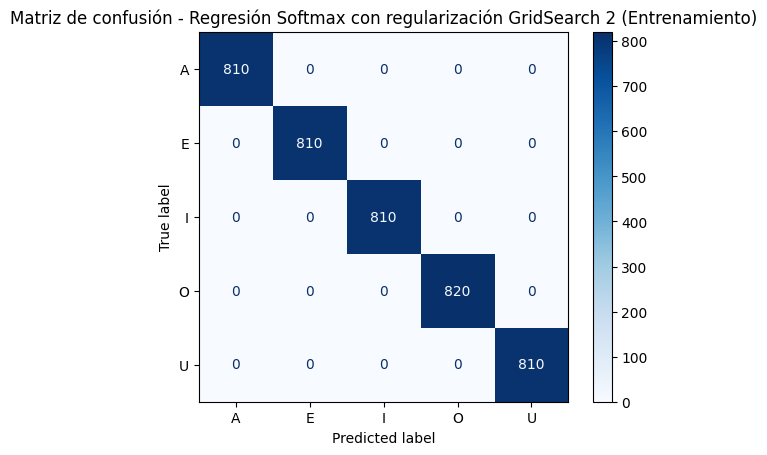

Modelo: Regresión Softmax con regularización GridSearch 2
Accuracy : 0.9812

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       200
           E     1.0000    0.9450    0.9717       200
           I     0.9346    1.0000    0.9662       200
           O     0.9763    0.9810    0.9786       210
           U     1.0000    0.9800    0.9899       200

    accuracy                         0.9812      1010
   macro avg     0.9822    0.9812    0.9813      1010
weighted avg     0.9821    0.9812    0.9813      1010



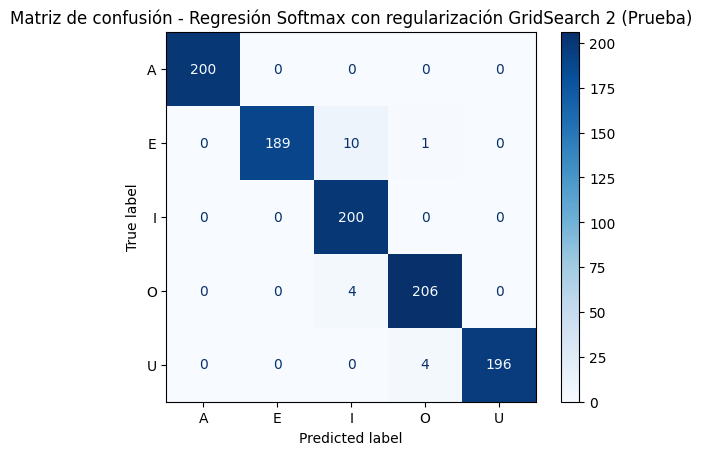

In [148]:
reg_grid2_pred_train = reg_grid2.predict(X_train_pca)
reg_grid2_pred_test = reg_grid2.predict(X_test_pca)

evaluar_modelo("Regresión Softmax con regularización GridSearch 2", "Entrenamiento", y_train, reg_grid2_pred_train)
evaluar_modelo("Regresión Softmax con regularización GridSearch 2", "Prueba", y_test, reg_grid2_pred_test)

En la segunda búsqueda la mejor combinación es nuevamente la regularización L2, ahora con `C=2`, con 97,02 % de accuracy promedio en validación, frente al 96,90 % de la primera búsqueda. Los cuatro valores de `C` con L2 quedan entre 96,89 % y 97,02 %, y los cuatro con L1 entre 95,64 % y 96,18 %, por lo que L2 vuelve a ser mejor en todos los casos.

El modelo seleccionado clasifica bien el 100 % de las imágenes de entrenamiento y el 98,12 % de las de prueba (991 de 1010), el mismo accuracy en prueba que el modelo de la primera búsqueda. La mejora de 0,12 puntos en validación no produjo un cambio en el conjunto de prueba.

#### 4.2.5 Comparación de los modelos de regresión

La siguiente tabla reúne el accuracy en entrenamiento y en prueba de los seis modelos de regresión Softmax, junto con la cantidad de imágenes de prueba mal clasificadas.

In [149]:
predicciones_reg = {"Regresión Softmax": (reg_sin_pred_train, reg_sin_pred_test),
                    "Regresión Softmax L2 (Ridge)": (reg_ridge_pred_train, reg_ridge_pred_test),
                    "Regresión Softmax L1 (Lasso)": (reg_lasso_pred_train, reg_lasso_pred_test),
                    "Regresión Softmax GridSearch": (reg_sin_grid_pred_train, reg_sin_grid_pred_test),
                    "Regresión Softmax con regularización GridSearch": (reg_grid_pred_train, reg_grid_pred_test),
                    "Regresión Softmax con regularización GridSearch 2": (reg_grid2_pred_train, reg_grid2_pred_test)}

filas = []
for nombre, (pred_train, pred_test) in predicciones_reg.items():
    filas.append({"Modelo": nombre,
                  "Accuracy entrenamiento": accuracy_score(y_train, pred_train),
                  "Accuracy prueba": accuracy_score(y_test, pred_test),
                  "Errores en prueba": (y_test != pred_test).sum()})

comparacion_reg = pd.DataFrame(filas)
display(comparacion_reg.round(4))

,Modelo,Accuracy entrenamiento,Accuracy prueba,Errores en prueba
0,Regresión Softmax,1.0000,0.9782,22
1,Regresión Softmax L2 (Ridge),0.9995,0.9832,17
2,Regresión Softmax L1 (Lasso),0.9901,0.9723,28
3,Regresión Softmax GridSearch,1.0000,0.9792,21
4,Regresión Softmax con regularización GridSearch,0.9995,0.9812,19
5,Regresión Softmax con regularización GridSearch 2,1.0000,0.9812,19


Los seis modelos quedan muy cerca entre sí: en prueba van de 97,23 % a 98,32 %, es decir, entre 17 y 28 errores en 1010 imágenes.

- El mayor accuracy en prueba es el del modelo con regularización L2 y `C=1` (98,32 %), y el menor es el del modelo con regularización L1 y `C=0.1` (97,23 %), que es también el único que queda por debajo de 99,9 % en entrenamiento.
- Los modelos sin regularización alcanzan 100 % en entrenamiento, pero en prueba (97,82 % y 97,92 %) quedan por debajo de los modelos con regularización L2 (entre 98,12 % y 98,32 %).
- En las búsquedas con `GridSearchCV` la regularización L2 fue mejor que la L1 en validación, y el accuracy promedio en validación de los modelos seleccionados fue casi el mismo: 96,95 % sin regularización, 96,90 % en la primera búsqueda con regularización y 97,02 % en la segunda.

Para la regresión Softmax, entonces, la regularización L2 da un resultado un poco mejor que no regularizar o que usar L1, y el ajuste de hiperparámetros produjo cambios muy pequeños, de 1 o 2 imágenes en el conjunto de prueba.

### 4.3 Árbol de decisión

Un árbol de decisión clasifica una imagen haciéndole una serie de preguntas sobre sus variables, por ejemplo si el valor de un componente principal es menor o igual que cierto número. Cada respuesta lleva a una nueva pregunta hasta llegar a una hoja, que indica la vocal.

#### Modelo base

Se entrena `DecisionTreeClassifier` con los valores por defecto: criterio `gini`, sin límite de profundidad (`max_depth=None`), `min_samples_split=2` y `min_samples_leaf=1`. Se fija `random_state=42` para que el resultado sea el mismo cada vez que se ejecuta el notebook.

In [150]:
arbol_base = DecisionTreeClassifier(random_state=42)
arbol_base.fit(X_train_pca, y_train)

print("Profundidad:", arbol_base.get_depth())
print("Número de hojas:", arbol_base.get_n_leaves())

Profundidad: 16
Número de hojas: 141


Modelo: Árbol de decisión
Accuracy : 1.0000

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       810
           E     1.0000    1.0000    1.0000       810
           I     1.0000    1.0000    1.0000       810
           O     1.0000    1.0000    1.0000       820
           U     1.0000    1.0000    1.0000       810

    accuracy                         1.0000      4060
   macro avg     1.0000    1.0000    1.0000      4060
weighted avg     1.0000    1.0000    1.0000      4060



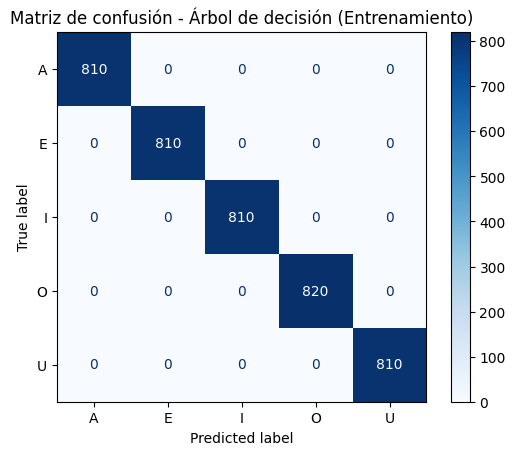

Modelo: Árbol de decisión
Accuracy : 0.9218

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     0.9490    0.9300    0.9394       200
           E     0.9742    0.9450    0.9594       200
           I     0.9190    0.9650    0.9415       200
           O     0.8692    0.8857    0.8774       210
           U     0.9031    0.8850    0.8939       200

    accuracy                         0.9218      1010
   macro avg     0.9229    0.9221    0.9223      1010
weighted avg     0.9224    0.9218    0.9219      1010



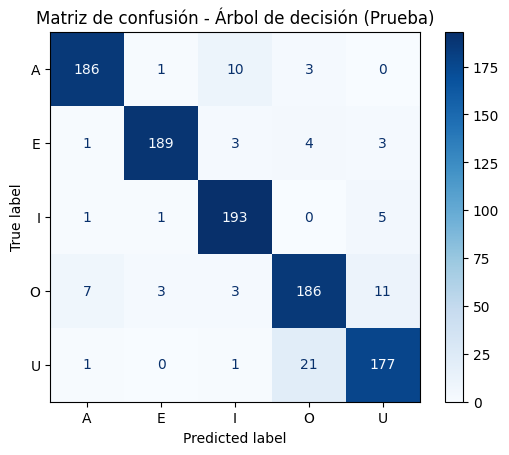

In [151]:
arbol_base_pred_train = arbol_base.predict(X_train_pca)
arbol_base_pred_test = arbol_base.predict(X_test_pca)

evaluar_modelo("Árbol de decisión", "Entrenamiento", y_train, arbol_base_pred_train)
evaluar_modelo("Árbol de decisión", "Prueba", y_test, arbol_base_pred_test)

In [152]:
val_arbol_base = cross_val_score(arbol_base, X_train_pca, y_train, groups=grupos_train,
                                 cv=validacion, scoring="accuracy")

print("Accuracy en cada parte de validación:", val_arbol_base.round(4))
print("Accuracy promedio en validación:", round(val_arbol_base.mean(), 4))
print("Desviación estándar:", round(val_arbol_base.std(), 4))

Accuracy en cada parte de validación: [0.8902 0.8593 0.8259 0.8457 0.9037]
Accuracy promedio en validación: 0.865
Desviación estándar: 0.0285


Sin ningún límite, el árbol base creció hasta una profundidad de 16 y tiene 141 hojas. Con ese tamaño clasifica bien el 100 % de las imágenes de entrenamiento, pero en prueba baja a 92,18 % (931 de 1010) y en validación cruzada a 86,50 % en promedio, con valores entre 82,59 % y 90,37 % según la parte. La diferencia entre entrenamiento y prueba es de 7,82 puntos, mucho mayor que la de la regresión Softmax (1,73 puntos): el árbol tiene sobreajuste, porque se ajustó por completo a las imágenes de entrenamiento y esas reglas no funcionan igual de bien con imágenes nuevas.

En la matriz de confusión de prueba los 79 errores están repartidos entre todas las vocales. Las confusiones más frecuentes son entre la O y la U (21 imágenes de la U clasificadas como O y 11 de la O clasificadas como U) y de la A con la I (10 imágenes de la A clasificadas como I). La O y la U son las vocales con el F1-score más bajo (0,8774 y 0,8939).

#### Ajuste de hiperparámetros con GridSearchCV

Los hiperparámetros que se ajustan son:

- `criterion`: la medida con la que el árbol elige cada pregunta, `gini` o `entropy` (entropía).
- `max_depth`: la profundidad máxima del árbol, es decir, cuántas preguntas seguidas puede hacer como máximo. Con `None` el árbol crece sin límite. Los valores se eligieron alrededor de la profundidad que alcanzó el árbol base (16).
- `min_samples_split`: la cantidad mínima de imágenes que debe tener un nodo para poder dividirse.
- `min_samples_leaf`: la cantidad mínima de imágenes que debe quedar en cada hoja.

Los tres últimos limitan el crecimiento del árbol, que es la forma de controlar el sobreajuste observado en el modelo base. En total son 90 combinaciones (2 × 5 × 3 × 3), entre ellas la del modelo base, y 450 entrenamientos.

In [153]:
parametros_arbol = {"criterion": ["gini", "entropy"],
                    "max_depth": [5, 10, 15, 20, None],
                    "min_samples_split": [2, 5, 10],
                    "min_samples_leaf": [1, 2, 4]}

In [154]:
grid_arbol = GridSearchCV(DecisionTreeClassifier(random_state=42), parametros_arbol,
                          scoring="accuracy", cv=validacion, return_train_score=True, n_jobs=-1)
grid_arbol.fit(X_train_pca, y_train, groups=grupos_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [5, 10, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_``

Como son 90 combinaciones, la tabla muestra las 10 con mayor accuracy promedio en validación.

In [155]:
resultados_arbol = pd.DataFrame(grid_arbol.cv_results_).rename(columns={"mean_test_score": "mean_val_score",
                                                                        "std_test_score": "std_val_score"})

display(resultados_arbol.sort_values(by="mean_val_score", ascending=False).head(10)[["param_criterion",
                                                                                     "param_max_depth",
                                                                                     "param_min_samples_split",
                                                                                     "param_min_samples_leaf",
                                                                                     "mean_train_score",
                                                                                     "mean_val_score",
                                                                                     "std_val_score"]].round(4))

,param_criterion,param_max_depth,param_min_samples_split,param_min_samples_leaf,mean_train_score,mean_val_score,std_val_score
89,entropy,None,10,4,0.9847,0.8793,0.0125
80,entropy,20,10,4,0.9847,0.8793,0.0125
71,entropy,15,10,4,0.9847,0.8793,0.0125
62,entropy,10,10,4,0.9818,0.8783,0.0131
63,entropy,15,2,1,1.0000,0.8779,0.0128
81,entropy,None,2,1,1.0000,0.8779,0.0128
72,entropy,20,2,1,1.0000,0.8779,0.0128
64,entropy,15,5,1,0.9970,0.8771,0.0121
82,entropy,None,5,1,0.9970,0.8771,0.0121
73,entropy,20,5,1,0.9970,0.8771,0.0121


In [156]:
print("Mejores hiperparámetros:", grid_arbol.best_params_)
print("Mejor accuracy promedio en validación:", round(grid_arbol.best_score_, 4))

arbol_grid = grid_arbol.best_estimator_

print("Profundidad:", arbol_grid.get_depth())
print("Número de hojas:", arbol_grid.get_n_leaves())

Mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 4, 'min_samples_split': 10}
Mejor accuracy promedio en validación: 0.8793
Profundidad: 14
Número de hojas: 107


Para ver el efecto de la profundidad se toman las combinaciones que tienen el mismo `criterion`, `min_samples_split` y `min_samples_leaf` del mejor modelo y se grafica el accuracy promedio de entrenamiento y de validación para cada valor de `max_depth`.

,param_max_depth,mean_train_score,mean_val_score
53,5,0.8872,0.8055
62,10,0.9818,0.8783
71,15,0.9847,0.8793
80,20,0.9847,0.8793
89,None,0.9847,0.8793


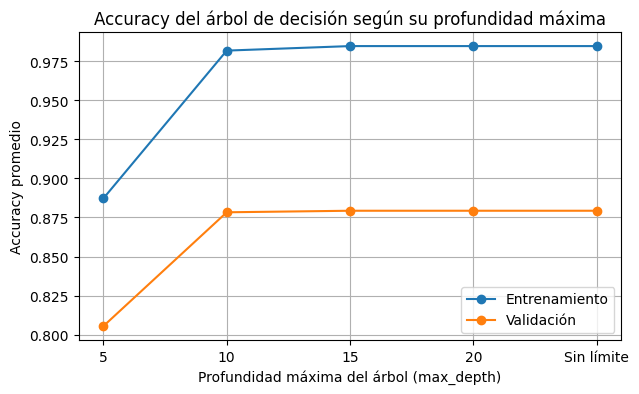

In [157]:
mejor = grid_arbol.best_params_
curva_arbol = resultados_arbol[(resultados_arbol["param_criterion"] == mejor["criterion"])
                               & (resultados_arbol["param_min_samples_split"] == mejor["min_samples_split"])
                               & (resultados_arbol["param_min_samples_leaf"] == mejor["min_samples_leaf"])]

display(curva_arbol[["param_max_depth", "mean_train_score", "mean_val_score"]].round(4))

profundidades = ["5", "10", "15", "20", "Sin límite"]

plt.figure(figsize=(7, 4))
plt.plot(profundidades, curva_arbol["mean_train_score"], marker="o", label="Entrenamiento")
plt.plot(profundidades, curva_arbol["mean_val_score"], marker="o", label="Validación")
plt.xlabel("Profundidad máxima del árbol (max_depth)")
plt.ylabel("Accuracy promedio")
plt.title("Accuracy del árbol de decisión según su profundidad máxima")
plt.legend()
plt.grid(True)
plt.show()

De la búsqueda se observa lo siguiente:

- La mejor combinación es `criterion="entropy"`, `max_depth=15`, `min_samples_split=10` y `min_samples_leaf=4`, con 87,93 % de accuracy promedio en validación, frente al 86,50 % del modelo base. Las 10 mejores combinaciones usan `entropy`.
- Hay un empate entre `max_depth=15`, `max_depth=20` y `max_depth=None` (las tres con 87,93 %). El árbol ajustado tiene una profundidad de 14, así que ninguno de esos tres límites llega a recortarlo y el resultado es el mismo árbol. Cuando hay un empate, `GridSearchCV` conserva la primera combinación de la rejilla, que en este caso es la de `max_depth=15`.
- En la gráfica, con `max_depth=5` el árbol es demasiado pequeño y tiene subajuste: 88,72 % en entrenamiento y 80,55 % en validación. Con `max_depth=10` sube a 98,18 % y 87,83 %, y a partir de 15 las dos curvas se quedan en 98,47 % y 87,93 %. Dar más profundidad no mejora la validación.
- En todas las profundidades hay una separación amplia entre la curva de entrenamiento y la de validación (alrededor de 10 puntos desde `max_depth=10`), es decir, el sobreajuste se mantiene aunque se limite el árbol.

#### Evaluación del modelo ajustado

Modelo: Árbol de decisión GridSearch
Accuracy : 0.9805

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     0.9722    0.9914    0.9817       810
           E     0.9841    0.9938    0.9889       810
           I     0.9887    0.9691    0.9788       810
           O     0.9664    0.9817    0.9740       820
           U     0.9924    0.9667    0.9794       810

    accuracy                         0.9805      4060
   macro avg     0.9807    0.9805    0.9806      4060
weighted avg     0.9807    0.9805    0.9805      4060



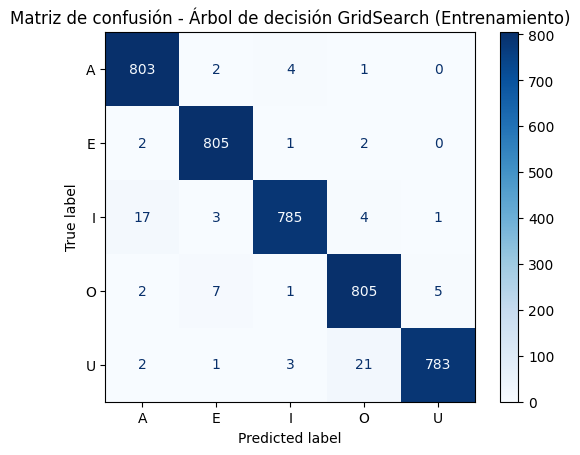

Modelo: Árbol de decisión GridSearch
Accuracy : 0.8851

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     0.8927    0.9150    0.9037       200
           E     0.9388    0.9200    0.9293       200
           I     0.8878    0.8700    0.8788       200
           O     0.8095    0.8905    0.8481       210
           U     0.9121    0.8300    0.8691       200

    accuracy                         0.8851      1010
   macro avg     0.8882    0.8851    0.8858      1010
weighted avg     0.8874    0.8851    0.8854      1010



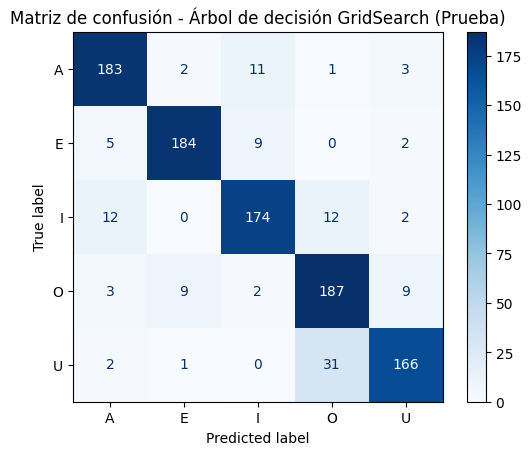

In [158]:
arbol_grid_pred_train = arbol_grid.predict(X_train_pca)
arbol_grid_pred_test = arbol_grid.predict(X_test_pca)

evaluar_modelo("Árbol de decisión GridSearch", "Entrenamiento", y_train, arbol_grid_pred_train)
evaluar_modelo("Árbol de decisión GridSearch", "Prueba", y_test, arbol_grid_pred_test)

El árbol ajustado tiene 107 hojas, por lo que no se puede leer completo en una figura. Se grafican los primeros niveles para ver cómo empieza a separar las vocales. En cada nodo, `CP` es el componente principal sobre el que se hace la pregunta, `samples` es la cantidad de imágenes que llegan al nodo y `value` es cuántas de ellas son de cada vocal, en el orden A, E, I, O, U.

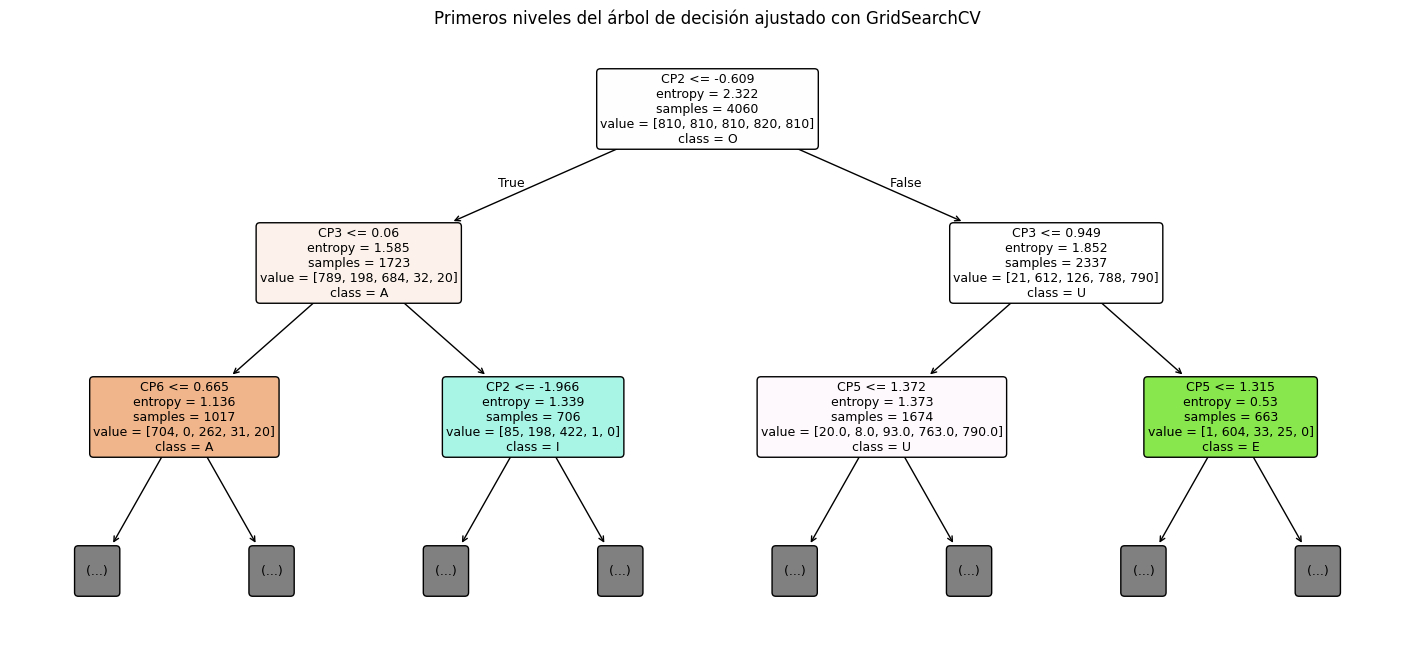

In [159]:
plt.figure(figsize=(18, 8))
plot_tree(arbol_grid, max_depth=2, feature_names=[f"CP{i + 1}" for i in range(X_train_pca.shape[1])],
          class_names=list(le.classes_), filled=True, rounded=True, fontsize=9)
plt.title("Primeros niveles del árbol de decisión ajustado con GridSearchCV")
plt.show()

In [160]:
comparacion_arbol = pd.DataFrame({"Modelo": ["Árbol de decisión", "Árbol de decisión GridSearch"],
                                  "Accuracy entrenamiento": [accuracy_score(y_train, arbol_base_pred_train),
                                                             accuracy_score(y_train, arbol_grid_pred_train)],
                                  "Accuracy validación": [val_arbol_base.mean(), grid_arbol.best_score_],
                                  "Accuracy prueba": [accuracy_score(y_test, arbol_base_pred_test),
                                                      accuracy_score(y_test, arbol_grid_pred_test)]})
display(comparacion_arbol.round(4))

,Modelo,Accuracy entrenamiento,Accuracy validación,Accuracy prueba
0,Árbol de decisión,1.0000,0.8650,0.9218
1,Árbol de decisión GridSearch,0.9805,0.8793,0.8851


El árbol ajustado es más pequeño que el base (profundidad 14 y 107 hojas, frente a 16 y 141) y ya no memoriza todas las imágenes de entrenamiento: su accuracy en entrenamiento baja de 100 % a 98,05 %. En validación mejora de 86,50 % a 87,93 %, pero en prueba baja de 92,18 % a 88,51 % (894 de 1010, con 116 errores frente a los 79 del modelo base). La confusión más frecuente sigue siendo la de la U con la O, que pasa de 21 a 31 imágenes.

La mejora en validación (1,44 puntos) es pequeña comparada con lo que cambia el accuracy del árbol base de una parte de validación a otra (entre 82,59 % y 90,37 %), y no se confirmó en el conjunto de prueba. Por lo tanto no se puede afirmar que el ajuste de hiperparámetros haya mejorado al árbol de decisión. Con cualquiera de las dos configuraciones el árbol queda por debajo de la regresión Softmax (98,22 % en prueba) y mantiene una diferencia amplia entre entrenamiento y prueba.

La figura muestra que la primera pregunta del árbol se hace sobre el componente principal 2 y las siguientes sobre los componentes 3, 5, 6 y nuevamente el 2, es decir, sobre los primeros componentes, que son los que conservan más varianza. Después de dos preguntas ningún nodo contiene una sola vocal, por eso el árbol necesita muchos más niveles para separarlas.

### 4.4 Random Forest

Random Forest entrena muchos árboles de decisión en lugar de uno solo. Cada árbol se entrena con una muestra distinta de las imágenes de entrenamiento, tomada al azar con reemplazo (bagging), y la predicción final se obtiene combinando las predicciones de todos los árboles.

#### Modelo base

Se entrena `RandomForestClassifier` con los valores por defecto: 100 árboles (`n_estimators=100`), criterio `gini`, sin límite de profundidad y `min_samples_leaf=1`. Se fija `random_state=42`.

In [161]:
bosque_base = RandomForestClassifier(random_state=42)
bosque_base.fit(X_train_pca, y_train)

profundidades_base = [arbol.get_depth() for arbol in bosque_base.estimators_]

print("Número de árboles:", bosque_base.n_estimators)
print("Profundidad promedio de los árboles:", np.mean(profundidades_base))

Número de árboles: 100
Profundidad promedio de los árboles: 17.33


Modelo: Random Forest
Accuracy : 1.0000

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       810
           E     1.0000    1.0000    1.0000       810
           I     1.0000    1.0000    1.0000       810
           O     1.0000    1.0000    1.0000       820
           U     1.0000    1.0000    1.0000       810

    accuracy                         1.0000      4060
   macro avg     1.0000    1.0000    1.0000      4060
weighted avg     1.0000    1.0000    1.0000      4060



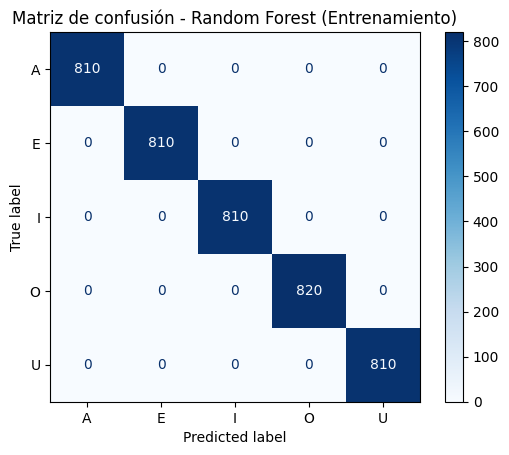

Modelo: Random Forest
Accuracy : 0.9842

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     0.9900    0.9900    0.9900       200
           E     0.9565    0.9900    0.9730       200
           I     0.9901    1.0000    0.9950       200
           O     1.0000    0.9429    0.9706       210
           U     0.9852    1.0000    0.9926       200

    accuracy                         0.9842      1010
   macro avg     0.9844    0.9846    0.9842      1010
weighted avg     0.9845    0.9842    0.9841      1010



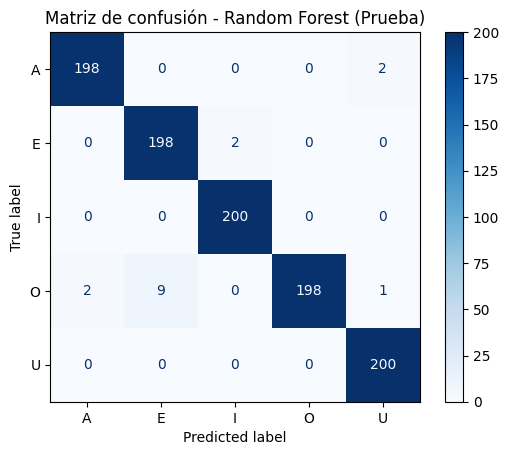

In [162]:
bosque_base_pred_train = bosque_base.predict(X_train_pca)
bosque_base_pred_test = bosque_base.predict(X_test_pca)

evaluar_modelo("Random Forest", "Entrenamiento", y_train, bosque_base_pred_train)
evaluar_modelo("Random Forest", "Prueba", y_test, bosque_base_pred_test)

In [163]:
val_bosque_base = cross_val_score(bosque_base, X_train_pca, y_train, groups=grupos_train,
                                  cv=validacion, scoring="accuracy")

print("Accuracy en cada parte de validación:", val_bosque_base.round(4))
print("Accuracy promedio en validación:", round(val_bosque_base.mean(), 4))
print("Desviación estándar:", round(val_bosque_base.std(), 4))

Accuracy en cada parte de validación: [0.9927 0.9679 0.9852 0.9667 0.9802]
Accuracy promedio en validación: 0.9785
Desviación estándar: 0.01


El modelo base tiene 100 árboles con una profundidad promedio de 17,33. Igual que el árbol individual, clasifica bien el 100 % de las imágenes de entrenamiento, pero en prueba alcanza 98,42 % (994 de 1010) y en validación cruzada 97,85 % en promedio, con una desviación estándar de 0,0100. Frente al árbol de decisión base, la diferencia entre entrenamiento y prueba se reduce de 7,82 a 1,58 puntos: combinar 100 árboles corrige gran parte del sobreajuste que tiene un árbol solo.

De los 16 errores en prueba, 12 son imágenes de la O (9 clasificadas como E, 2 como A y 1 como U), por lo que la O tiene el recall más bajo (0,9429). La I y la U fueron clasificadas correctamente en todas sus imágenes.

#### Ajuste de hiperparámetros con GridSearchCV

Los hiperparámetros que se ajustan son:

- `n_estimators`: la cantidad de árboles del bosque. Se prueba el valor por defecto (100) y dos valores mayores.
- `criterion`: `gini` o `entropy`, igual que en el árbol de decisión.
- `max_depth`: la profundidad máxima de cada árbol. Se prueba sin límite y con dos límites, uno por debajo y otro por encima de la profundidad promedio de los árboles del modelo base (17,33).
- `min_samples_leaf`: la cantidad mínima de imágenes en cada hoja.

En total son 36 combinaciones (3 × 2 × 3 × 2), entre ellas la del modelo base, y 180 entrenamientos.

In [197]:
parametros_bosque = {"n_estimators": [100, 200, 300],
                     "criterion": ["gini", "entropy"],
                     "max_depth": [10, 20, None],
                     "min_samples_leaf": [1, 2]}

In [198]:
grid_bosque = GridSearchCV(RandomForestClassifier(random_state=42), parametros_bosque,
                           scoring="accuracy", cv=validacion, return_train_score=True, n_jobs=-1)
grid_bosque.fit(X_train_pca, y_train, groups=grupos_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [10, 20, ...], 'min_samples_leaf': [1, 2], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will

La tabla muestra las 10 combinaciones con mayor accuracy promedio en validación.

In [199]:
resultados_bosque = pd.DataFrame(grid_bosque.cv_results_).rename(columns={"mean_test_score": "mean_val_score",
                                                                          "std_test_score": "std_val_score"})

display(resultados_bosque.sort_values(by="mean_val_score", ascending=False).head(10)[["param_n_estimators",
                                                                                      "param_criterion",
                                                                                      "param_max_depth",
                                                                                      "param_min_samples_leaf",
                                                                                      "mean_train_score",
                                                                                      "mean_val_score",
                                                                                      "std_val_score"]].round(4))

,param_n_estimators,param_criterion,param_max_depth,param_min_samples_leaf,mean_train_score,mean_val_score,std_val_score
26,300,entropy,20,1,1.0,0.9835,0.0066
25,200,entropy,20,1,1.0,0.9835,0.0074
2,300,gini,10,1,1.0,0.9835,0.0099
31,200,entropy,None,1,1.0,0.9832,0.0074
32,300,entropy,None,1,1.0,0.9832,0.0066
1,200,gini,10,1,1.0,0.9827,0.0088
8,300,gini,20,1,1.0,0.9822,0.0075
14,300,gini,None,1,1.0,0.9822,0.0077
23,300,entropy,10,2,1.0,0.9820,0.0068
22,200,entropy,10,2,1.0,0.9815,0.0052


In [200]:
print("Mejores hiperparámetros:", grid_bosque.best_params_)
print("Mejor accuracy promedio en validación:", round(grid_bosque.best_score_, 4))
print("Menor accuracy promedio en validación de la rejilla:", round(resultados_bosque["mean_val_score"].min(), 4))

bosque_grid = grid_bosque.best_estimator_

profundidades_grid = [arbol.get_depth() for arbol in bosque_grid.estimators_]

print("Número de árboles:", bosque_grid.n_estimators)
print("Profundidad promedio de los árboles:", np.mean(profundidades_grid))

Mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}
Mejor accuracy promedio en validación: 0.9835
Menor accuracy promedio en validación de la rejilla: 0.9761
Número de árboles: 200
Profundidad promedio de los árboles: 14.99


La combinación seleccionada es `n_estimators=200`, `criterion="entropy"`, `max_depth=20` y `min_samples_leaf=1`, con 98,35 % de accuracy promedio en validación, frente al 97,85 % del modelo base. En la tabla hay otras dos combinaciones que también aparecen con 98,35 %; cuando hay un empate, `GridSearchCV` conserva la primera combinación de la rejilla. Con la configuración seleccionada los árboles tienen una profundidad promedio de 14,99.

Los hiperparámetros influyen poco en este modelo: las 36 combinaciones quedaron entre 97,61 % y 98,35 % en validación, una diferencia de 0,74 puntos entre la peor y la mejor. Entre las 10 mejores, las 8 primeras usan `min_samples_leaf=1` y ninguna tiene 100 árboles, por lo que aumentar la cantidad de árboles sí ayudó, aunque poco. Todas las combinaciones de la tabla tienen 100 % de accuracy en entrenamiento.

#### Evaluación del modelo ajustado

Modelo: Random Forest GridSearch
Accuracy : 1.0000

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       810
           E     1.0000    1.0000    1.0000       810
           I     1.0000    1.0000    1.0000       810
           O     1.0000    1.0000    1.0000       820
           U     1.0000    1.0000    1.0000       810

    accuracy                         1.0000      4060
   macro avg     1.0000    1.0000    1.0000      4060
weighted avg     1.0000    1.0000    1.0000      4060



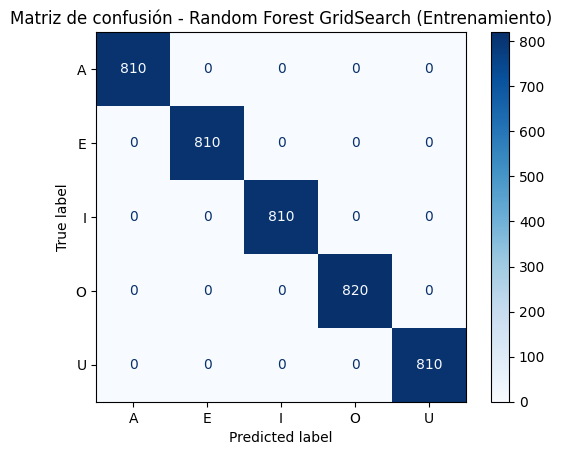

Modelo: Random Forest GridSearch
Accuracy : 0.9901

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     0.9950    1.0000    0.9975       200
           E     0.9614    0.9950    0.9779       200
           I     0.9950    1.0000    0.9975       200
           O     1.0000    0.9571    0.9781       210
           U     1.0000    1.0000    1.0000       200

    accuracy                         0.9901      1010
   macro avg     0.9903    0.9904    0.9902      1010
weighted avg     0.9904    0.9901    0.9901      1010



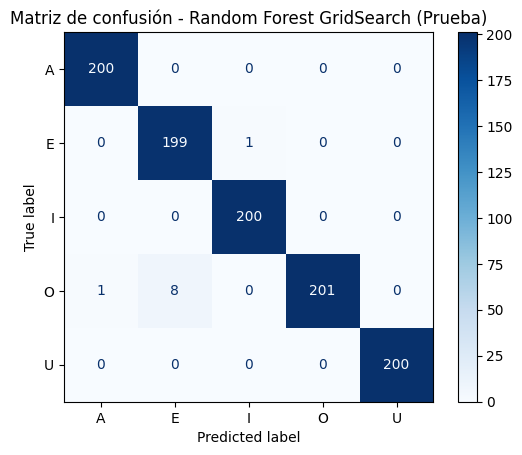

In [201]:
bosque_grid_pred_train = bosque_grid.predict(X_train_pca)
bosque_grid_pred_test = bosque_grid.predict(X_test_pca)

evaluar_modelo("Random Forest GridSearch", "Entrenamiento", y_train, bosque_grid_pred_train)
evaluar_modelo("Random Forest GridSearch", "Prueba", y_test, bosque_grid_pred_test)

In [202]:
comparacion_bosque = pd.DataFrame({"Modelo": ["Random Forest", "Random Forest GridSearch"],
                                   "Accuracy entrenamiento": [accuracy_score(y_train, bosque_base_pred_train),
                                                              accuracy_score(y_train, bosque_grid_pred_train)],
                                   "Accuracy validación": [val_bosque_base.mean(), grid_bosque.best_score_],
                                   "Accuracy prueba": [accuracy_score(y_test, bosque_base_pred_test),
                                                       accuracy_score(y_test, bosque_grid_pred_test)]})
display(comparacion_bosque.round(4))

,Modelo,Accuracy entrenamiento,Accuracy validación,Accuracy prueba
0,Random Forest,1.0,0.9785,0.9842
1,Random Forest GridSearch,1.0,0.9835,0.9901


El modelo ajustado mantiene el 100 % en entrenamiento y mejora tanto en validación (de 97,85 % a 98,42 %) como en prueba, donde pasa de 98,42 % a 99,01 %: clasifica bien 1000 de las 1010 imágenes y los errores bajan de 16 a 10. A diferencia de lo que ocurrió con el árbol de decisión, aquí la mejora que se vio en validación también se observa en prueba.

### 4.5 Red neuronal MLP

Un perceptrón multicapa (MLP) es una red neuronal formada por una capa de entrada (las 76 variables de cada imagen), una o varias capas ocultas de neuronas y una capa de salida con una neurona por cada vocal. Cada neurona combina los valores que recibe y les aplica una función de activación. Durante el entrenamiento la red ajusta sus pesos en cada iteración para reducir la función de pérdida, que mide qué tan lejos están sus predicciones de las etiquetas reales.

#### Modelo base

Se entrena `MLPClassifier` con los valores por defecto: una capa oculta de 100 neuronas, función de activación ReLU, `alpha=0.0001` y `learning_rate_init=0.001`. Se fija `max_iter=500` como máximo de iteraciones y `random_state=42`.

In [203]:
mlp_base = MLPClassifier(max_iter=500, random_state=42)
mlp_base.fit(X_train_pca, y_train)

print("Número de iteraciones:", mlp_base.n_iter_)
print("Valor final de la pérdida:", round(mlp_base.loss_, 4))

Número de iteraciones: 63
Valor final de la pérdida: 0.0017


Modelo: MLP
Accuracy : 1.0000

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       810
           E     1.0000    1.0000    1.0000       810
           I     1.0000    1.0000    1.0000       810
           O     1.0000    1.0000    1.0000       820
           U     1.0000    1.0000    1.0000       810

    accuracy                         1.0000      4060
   macro avg     1.0000    1.0000    1.0000      4060
weighted avg     1.0000    1.0000    1.0000      4060



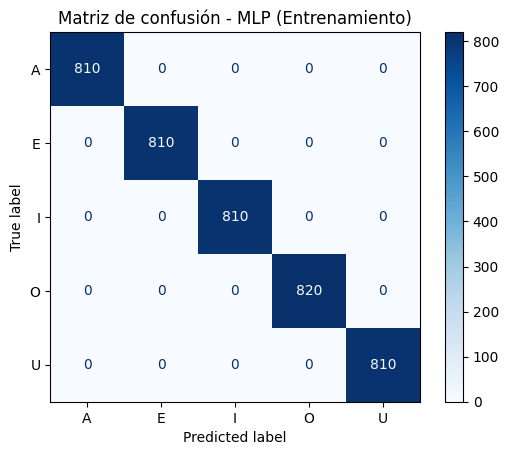

Modelo: MLP
Accuracy : 0.9861

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       200
           E     1.0000    0.9500    0.9744       200
           I     0.9524    1.0000    0.9756       200
           O     1.0000    0.9810    0.9904       210
           U     0.9804    1.0000    0.9901       200

    accuracy                         0.9861      1010
   macro avg     0.9866    0.9862    0.9861      1010
weighted avg     0.9867    0.9861    0.9861      1010



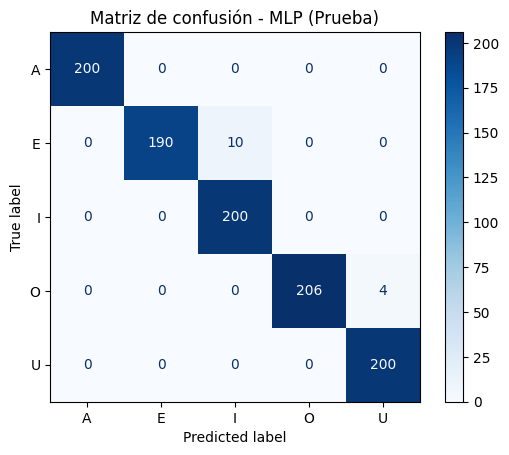

In [204]:
mlp_base_pred_train = mlp_base.predict(X_train_pca)
mlp_base_pred_test = mlp_base.predict(X_test_pca)

evaluar_modelo("MLP", "Entrenamiento", y_train, mlp_base_pred_train)
evaluar_modelo("MLP", "Prueba", y_test, mlp_base_pred_test)

In [205]:
val_mlp_base = cross_val_score(mlp_base, X_train_pca, y_train, groups=grupos_train,
                               cv=validacion, scoring="accuracy")

print("Accuracy en cada parte de validación:", val_mlp_base.round(4))
print("Accuracy promedio en validación:", round(val_mlp_base.mean(), 4))
print("Desviación estándar:", round(val_mlp_base.std(), 4))

Accuracy en cada parte de validación: [0.9927 0.9963 0.984  0.958  0.9852]
Accuracy promedio en validación: 0.9832
Desviación estándar: 0.0134


El entrenamiento del modelo base terminó en 63 iteraciones, sin llegar al máximo de 500, con una pérdida final de 0,0017. El modelo clasifica bien el 100 % de las imágenes de entrenamiento y el 98,61 % de las de prueba (996 de 1010), con una diferencia de 1,39 puntos entre los dos conjuntos. En validación cruzada el promedio es de 98,32 %, con una desviación estándar de 0,0134.

Los 14 errores en prueba son de dos tipos: 10 imágenes de la E clasificadas como I y 4 de la O clasificadas como U. La A, la I y la U tienen recall de 1,0000. La confusión de 10 imágenes de la E con la I es la misma cantidad que apareció en los modelos de regresión Softmax sin regularización y con L2.

#### Ajuste de hiperparámetros con GridSearchCV

Los hiperparámetros que se ajustan son:

- `hidden_layer_sizes`: la cantidad de capas ocultas y de neuronas. Se prueba una capa de 50 neuronas, una capa de 100 (el valor por defecto) y dos capas de 100 y 50 neuronas.
- `activation`: la función de activación de las neuronas, `relu` o `tanh`.
- `alpha`: la fuerza de la regularización L2. A diferencia de `C` en la regresión, aquí un valor mayor aplica más regularización.
- `learning_rate_init`: la tasa de aprendizaje, que define qué tan grande es el cambio de los pesos en cada paso del entrenamiento.

En total son 24 combinaciones (3 × 2 × 2 × 2), entre ellas la del modelo base, y 120 entrenamientos.

In [207]:
parametros_mlp = {"hidden_layer_sizes": [(50,), (100,), (100, 50)],
                  "activation": ["relu", "tanh"],
                  "alpha": [0.0001, 0.01],
                  "learning_rate_init": [0.001, 0.01]}

In [208]:
grid_mlp = GridSearchCV(MLPClassifier(max_iter=500, random_state=42), parametros_mlp,
                        scoring="accuracy", cv=validacion, return_train_score=True, n_jobs=-1)
grid_mlp.fit(X_train_pca, y_train, groups=grupos_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",MLPClassifier...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'activation': ['relu', 'tanh'], 'alpha': [0.0001, 0.01], 'hidden_layer_sizes': [(50,), (100,), ...], 'learning_rate_init': [0.001, 0.01]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best

La tabla muestra las 24 combinaciones ordenadas de mayor a menor accuracy promedio en validación.

In [209]:
resultados_mlp = pd.DataFrame(grid_mlp.cv_results_).rename(columns={"mean_test_score": "mean_val_score",
                                                                    "std_test_score": "std_val_score"})

display(resultados_mlp.sort_values(by="mean_val_score", ascending=False)[["param_hidden_layer_sizes",
                                                                           "param_activation",
                                                                           "param_alpha",
                                                                           "param_learning_rate_init",
                                                                           "mean_train_score",
                                                                           "mean_val_score",
                                                                           "std_val_score"]].round(4))

,param_hidden_layer_sizes,param_activation,param_alpha,param_learning_rate_init,mean_train_score,mean_val_score,std_val_score
10,"(100, 50)",relu,0.0100,0.001,1.0,0.9857,0.0117
7,"(50,)",relu,0.0100,0.010,1.0,0.9855,0.0109
4,"(100, 50)",relu,0.0001,0.001,1.0,0.9852,0.0133
11,"(100, 50)",relu,0.0100,0.010,1.0,0.9852,0.0117
9,"(100,)",relu,0.0100,0.010,1.0,0.9845,0.0103
6,"(50,)",relu,0.0100,0.001,1.0,0.9840,0.0108
3,"(100,)",relu,0.0001,0.010,1.0,0.9837,0.0114
0,"(50,)",relu,0.0001,0.001,1.0,0.9832,0.0101
8,"(100,)",relu,0.0100,0.001,1.0,0.9832,0.0128
2,"(100,)",relu,0.0001,0.001,1.0,0.9832,0.0134


In [210]:
print("Mejores hiperparámetros:", grid_mlp.best_params_)
print("Mejor accuracy promedio en validación:", round(grid_mlp.best_score_, 4))

mlp_grid = grid_mlp.best_estimator_

print("Número de iteraciones:", mlp_grid.n_iter_)
print("Valor final de la pérdida:", round(mlp_grid.loss_, 4))

Mejores hiperparámetros: {'activation': 'relu', 'alpha': 0.01, 'hidden_layer_sizes': (100, 50), 'learning_rate_init': 0.001}
Mejor accuracy promedio en validación: 0.9857
Número de iteraciones: 38
Valor final de la pérdida: 0.0058


La mejor combinación es una red con dos capas ocultas de 100 y 50 neuronas, activación `relu`, `alpha=0.01` y `learning_rate_init=0.001`, con 98,57 % de accuracy promedio en validación, frente al 98,32 % del modelo base.

Las 24 combinaciones quedaron muy cerca unas de otras, entre 97,54 % y 98,57 %, y todas tienen 100 % de accuracy promedio en entrenamiento. El hiperparámetro que más separa los resultados es la función de activación: las 12 combinaciones con `relu` ocupan las 12 primeras posiciones (de 98,25 % a 98,57 %) y las 12 con `tanh` las 12 últimas (de 97,54 % a 98,05 %).

Las curvas de pérdida muestran cómo disminuye el error de cada red durante su entrenamiento.

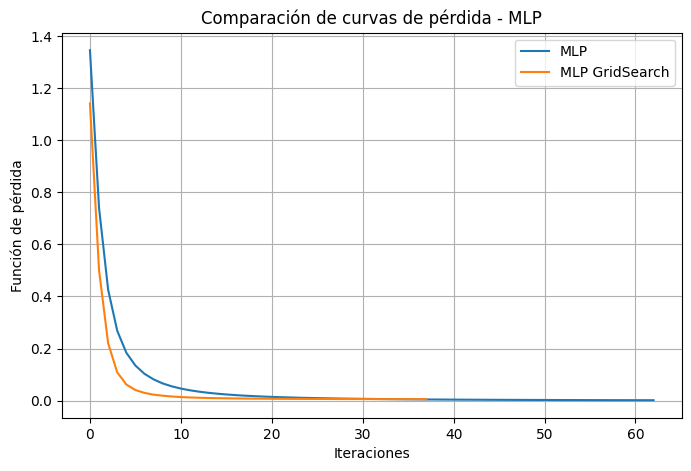

In [211]:
plt.figure(figsize=(8, 5))
plt.plot(mlp_base.loss_curve_, label="MLP")
plt.plot(mlp_grid.loss_curve_, label="MLP GridSearch")
plt.xlabel("Iteraciones")
plt.ylabel("Función de pérdida")
plt.title("Comparación de curvas de pérdida - MLP")
plt.legend()
plt.grid(True)
plt.show()

En las dos redes la pérdida cae rápidamente en las primeras iteraciones y después se estabiliza cerca de cero, lo que muestra que el entrenamiento convergió. El modelo ajustado necesitó menos iteraciones que el base (38 frente a 63) y terminó con una pérdida un poco mayor (0,0058 frente a 0,0017).

#### Evaluación del modelo ajustado

Modelo: MLP GridSearch
Accuracy : 1.0000

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       810
           E     1.0000    1.0000    1.0000       810
           I     1.0000    1.0000    1.0000       810
           O     1.0000    1.0000    1.0000       820
           U     1.0000    1.0000    1.0000       810

    accuracy                         1.0000      4060
   macro avg     1.0000    1.0000    1.0000      4060
weighted avg     1.0000    1.0000    1.0000      4060



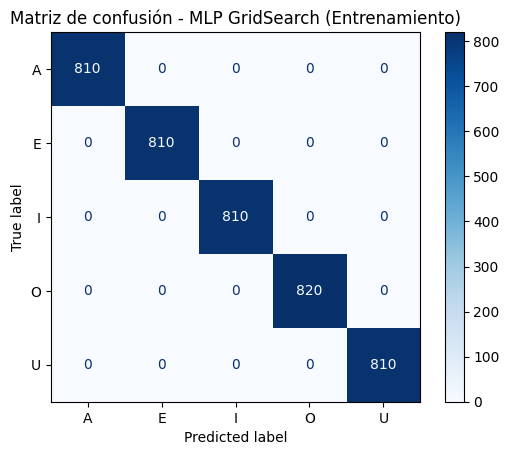

Modelo: MLP GridSearch
Accuracy : 0.9851

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       200
           E     1.0000    0.9500    0.9744       200
           I     0.9524    1.0000    0.9756       200
           O     1.0000    0.9762    0.9880       210
           U     0.9756    1.0000    0.9877       200

    accuracy                         0.9851      1010
   macro avg     0.9856    0.9852    0.9851      1010
weighted avg     0.9857    0.9851    0.9851      1010



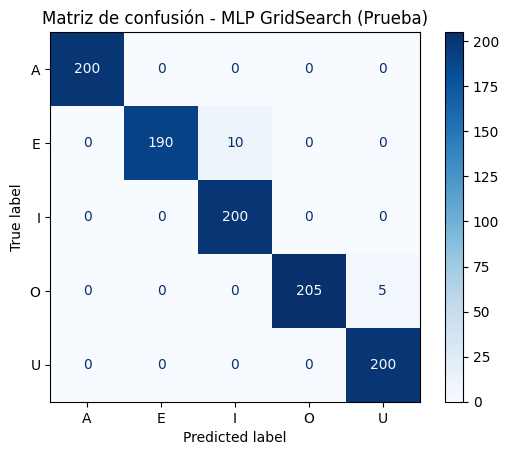

In [212]:
mlp_grid_pred_train = mlp_grid.predict(X_train_pca)
mlp_grid_pred_test = mlp_grid.predict(X_test_pca)

evaluar_modelo("MLP GridSearch", "Entrenamiento", y_train, mlp_grid_pred_train)
evaluar_modelo("MLP GridSearch", "Prueba", y_test, mlp_grid_pred_test)

In [213]:
comparacion_mlp = pd.DataFrame({"Modelo": ["MLP", "MLP GridSearch"],
                                "Accuracy entrenamiento": [accuracy_score(y_train, mlp_base_pred_train),
                                                           accuracy_score(y_train, mlp_grid_pred_train)],
                                "Accuracy validación": [val_mlp_base.mean(), grid_mlp.best_score_],
                                "Accuracy prueba": [accuracy_score(y_test, mlp_base_pred_test),
                                                    accuracy_score(y_test, mlp_grid_pred_test)]})
display(comparacion_mlp.round(4))

,Modelo,Accuracy entrenamiento,Accuracy validación,Accuracy prueba
0,MLP,1.0,0.9832,0.9861
1,MLP GridSearch,1.0,0.9857,0.9851


El modelo ajustado mantiene el 100 % en entrenamiento y sube en validación de 98,32 % a 98,57 %, pero en prueba queda prácticamente igual que el base: 98,51 % frente a 98,61 %, es decir, 15 errores en lugar de 14. La matriz de confusión es casi la misma: las 10 imágenes de la E clasificadas como I y 5 de la O clasificadas como U (una más que en el modelo base).

Una diferencia de una sola imagen entre 1010 no permite decir que un modelo sea mejor que el otro. Para el MLP el ajuste de hiperparámetros produjo una mejora de 0,25 puntos en validación que no se reflejó en el conjunto de prueba.

### 4.6 Red neuronal profunda (DNN)

Una red neuronal profunda (DNN) es una red neuronal con varias capas ocultas, una después de la otra. Se construye con Keras, donde la red se arma capa por capa. La función `crear_dnn` arma la red de la siguiente forma:

- Una capa de entrada que recibe las 76 variables de cada imagen.
- Varias capas ocultas `Dense`, en las que cada neurona está conectada con todas las neuronas de la capa anterior. La cantidad de capas (`capas_ocultas`) y de neuronas por capa (`neuronas`) son parámetros de la función. Todas usan la función de activación ReLU.
- Si `dropout` es mayor que 0, después de cada capa oculta se agrega una capa `Dropout`, que apaga al azar esa proporción de neuronas en cada paso del entrenamiento. Es una forma de reducir el sobreajuste.
- Una capa de salida con 5 neuronas, una por vocal, con la función Softmax, que entrega la probabilidad de cada vocal.

Al compilar la red se indica la función de pérdida `sparse_categorical_crossentropy`, que es la que corresponde cuando las clases están codificadas como números enteros (de 0 a 4), como quedaron con el Integer Encoding. También se indica el optimizador Adam, con su tasa de aprendizaje (`learning_rate`).

In [214]:
def crear_dnn(capas_ocultas=3, neuronas=64, dropout=0.0, learning_rate=0.001):
    modelo = keras.Sequential()
    modelo.add(keras.layers.Input(shape=(X_train_pca.shape[1],)))

    for _ in range(capas_ocultas):
        modelo.add(keras.layers.Dense(neuronas, activation="relu"))
        if dropout > 0:
            modelo.add(keras.layers.Dropout(dropout))

    modelo.add(keras.layers.Dense(len(le.classes_), activation="softmax"))

    modelo.compile(loss="sparse_categorical_crossentropy",
                   optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                   metrics=["accuracy"])
    return modelo

`KerasClassifier`, de la librería scikeras, permite usar la red de Keras con las mismas funciones que los demás modelos: `fit`, `predict`, `cross_val_score` y `GridSearchCV`.

#### Modelo base

A diferencia de los modelos anteriores, en Keras la red no trae una arquitectura por defecto, así que el modelo base es una configuración inicial: 3 capas ocultas de 64 neuronas, sin dropout y con una tasa de aprendizaje de 0,001, que es el valor por defecto de Adam. La red se entrena durante 30 épocas (una época es una pasada completa por todas las imágenes de entrenamiento) con `batch_size=32`, es decir, los pesos se actualizan cada 32 imágenes. Se fija `random_state=42`.

In [215]:
dnn_base = KerasClassifier(model=crear_dnn, epochs=30, batch_size=32, verbose=0, random_state=42)
dnn_base.fit(X_train_pca, y_train)

dnn_base.model_.summary()

Model: "sequential_254"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1016 (Dense)              │ (None, 64)             │         4,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1017 (Dense)              │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1018 (Dense)              │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1019 (Dense)              │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,721 (159.07 KB)

 Trainable params: 13,573 (53.02 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 27,148 (106.05 KB)

El resumen muestra las tres capas ocultas de 64 neuronas y la capa de salida de 5 neuronas. La red tiene 13 573 parámetros entrenables, que son los pesos que se ajustan durante el entrenamiento.

Las siguientes gráficas muestran la función de pérdida y el accuracy sobre las imágenes de entrenamiento en cada época.

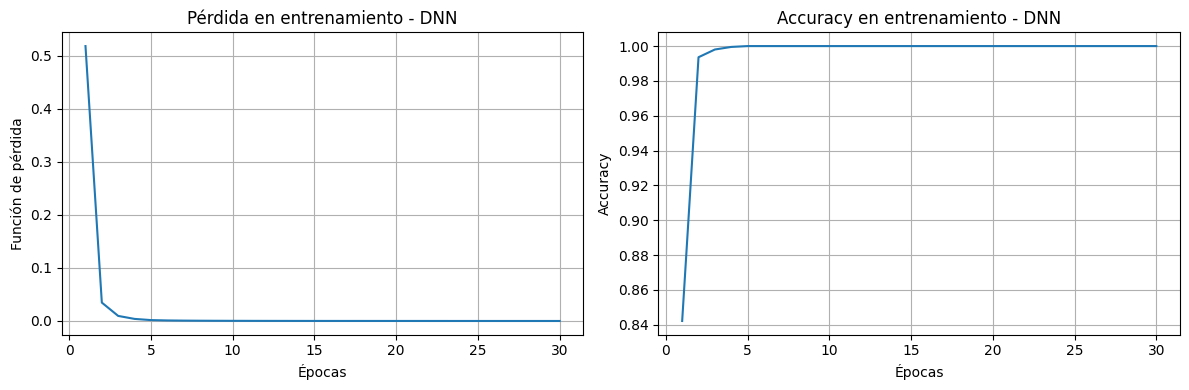

Pérdida en la última época: 1.7e-05
Primera época con accuracy de 1.0 en entrenamiento: 5


In [216]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, 31), dnn_base.history_["loss"])
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Función de pérdida")
axes[0].set_title("Pérdida en entrenamiento - DNN")
axes[0].grid(True)

axes[1].plot(range(1, 31), dnn_base.history_["accuracy"])
axes[1].set_xlabel("Épocas")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy en entrenamiento - DNN")
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Pérdida en la última época:", round(dnn_base.history_["loss"][-1], 6))
print("Primera época con accuracy de 1.0 en entrenamiento:",
      int(np.argmax(np.array(dnn_base.history_["accuracy"]) == 1.0)) + 1)

Modelo: DNN
Accuracy : 1.0000

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       810
           E     1.0000    1.0000    1.0000       810
           I     1.0000    1.0000    1.0000       810
           O     1.0000    1.0000    1.0000       820
           U     1.0000    1.0000    1.0000       810

    accuracy                         1.0000      4060
   macro avg     1.0000    1.0000    1.0000      4060
weighted avg     1.0000    1.0000    1.0000      4060



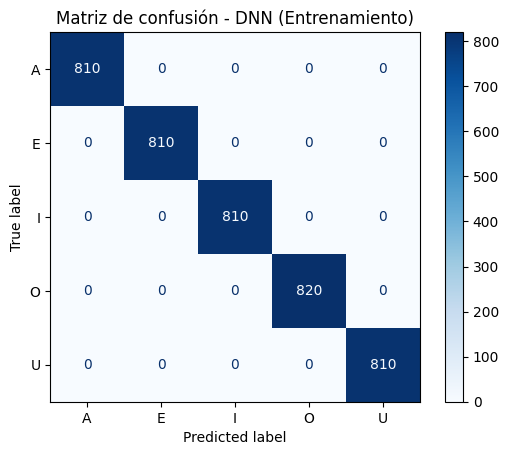

Modelo: DNN
Accuracy : 0.9891

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       200
           E     1.0000    0.9500    0.9744       200
           I     0.9524    1.0000    0.9756       200
           O     1.0000    0.9952    0.9976       210
           U     0.9950    1.0000    0.9975       200

    accuracy                         0.9891      1010
   macro avg     0.9895    0.9890    0.9890      1010
weighted avg     0.9896    0.9891    0.9891      1010



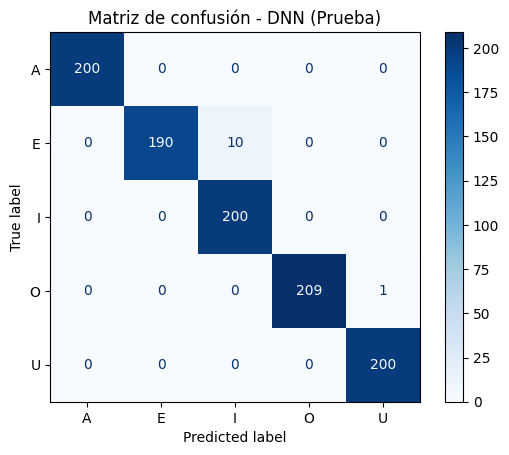

In [217]:
dnn_base_pred_train = dnn_base.predict(X_train_pca)
dnn_base_pred_test = dnn_base.predict(X_test_pca)

evaluar_modelo("DNN", "Entrenamiento", y_train, dnn_base_pred_train)
evaluar_modelo("DNN", "Prueba", y_test, dnn_base_pred_test)

In [218]:
val_dnn_base = cross_val_score(dnn_base, X_train_pca, y_train, groups=grupos_train,
                               cv=validacion, scoring="accuracy")

print("Accuracy en cada parte de validación:", val_dnn_base.round(4))
print("Accuracy promedio en validación:", round(val_dnn_base.mean(), 4))
print("Desviación estándar:", round(val_dnn_base.std(), 4))

Accuracy en cada parte de validación: [0.989  0.9938 0.9926 0.9593 0.9877]
Accuracy promedio en validación: 0.9845
Desviación estándar: 0.0128


La pérdida cae rápidamente en las primeras épocas y en la época 5 la red ya clasifica bien el 100 % de las imágenes de entrenamiento. Desde ahí las dos curvas se mantienen estables hasta la época 30, donde la pérdida es de 0,000017, lo que muestra que 30 épocas son suficientes para que el entrenamiento converja.

El modelo base obtiene 100 % de accuracy en entrenamiento y 98,91 % en prueba (999 de 1010), con una diferencia de 1,09 puntos entre los dos conjuntos. En validación cruzada el promedio es de 98,45 %, con una desviación estándar de 0,0128.

De los 11 errores en prueba, 10 son imágenes de la E clasificadas como I y el otro es una imagen de la O clasificada como U. La confusión de 10 imágenes de la E con la I es la misma cantidad que se observó en el MLP y en los modelos de regresión Softmax sin regularización y con L2.

#### Ajuste de hiperparámetros con GridSearchCV

Los hiperparámetros que se ajustan son:

- `n_estimators`: la cantidad de árboles del bosque. Se prueba el valor por defecto (100) y dos valores mayores.
- `criterion`: `gini` o `entropy`, igual que en el árbol de decisión.
- `max_depth`: la profundidad máxima de cada árbol. Se prueba sin límite y con dos límites, uno por debajo y otro por encima de la profundidad promedio de los árboles del modelo base (17,33).
- `min_samples_leaf`: la cantidad mínima de imágenes en cada hoja.

En total son 36 combinaciones (3 × 2 × 3 × 2), entre ellas la del modelo base, y 180 entrenamientos.

In [219]:
parametros_dnn = {"model__capas_ocultas": [2, 3, 4],
                  "model__neuronas": [64, 128],
                  "model__dropout": [0.0, 0.2],
                  "model__learning_rate": [0.001, 0.01]}

In [220]:
grid_dnn = GridSearchCV(KerasClassifier(model=crear_dnn, epochs=30, batch_size=32, verbose=0, random_state=42),
                        parametros_dnn, scoring="accuracy", cv=validacion, return_train_score=True)
grid_dnn.fit(X_train_pca, y_train, groups=grupos_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KerasClassifi..._weight=None )
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__capas_ocultas': [2, 3, ...], 'model__dropout': [0.0, 0.2], 'model__learning_rate': [0.001, 0.01], 'model__neuronas': [64, 128]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best

La tabla muestra las 24 combinaciones ordenadas de mayor a menor accuracy promedio en validación.

In [187]:
resultados_dnn = pd.DataFrame(grid_dnn.cv_results_).rename(columns={"mean_test_score": "mean_val_score",
                                                                    "std_test_score": "std_val_score"})

display(resultados_dnn.sort_values(by="mean_val_score", ascending=False)[["param_model__capas_ocultas",
                                                                           "param_model__neuronas",
                                                                           "param_model__dropout",
                                                                           "param_model__learning_rate",
                                                                           "mean_train_score",
                                                                           "mean_val_score",
                                                                           "std_val_score"]].round(4))

,param_model__capas_ocultas,param_model__neuronas,param_model__dropout,param_model__learning_rate,mean_train_score,mean_val_score,std_val_score
9,3,128,0.0,0.001,1.0000,0.9864,0.0130
10,3,64,0.0,0.010,1.0000,0.9862,0.0091
17,4,128,0.0,0.001,1.0000,0.9855,0.0127
21,4,128,0.2,0.001,0.9999,0.9854,0.0079
1,2,128,0.0,0.001,1.0000,0.9847,0.0144
8,3,64,0.0,0.001,1.0000,0.9845,0.0128
13,3,128,0.2,0.001,0.9999,0.9835,0.0109
20,4,64,0.2,0.001,1.0000,0.9830,0.0108
18,4,64,0.0,0.010,1.0000,0.9825,0.0082
19,4,128,0.0,0.010,1.0000,0.9823,0.0079


In [188]:
print("Mejores hiperparámetros:", grid_dnn.best_params_)
print("Mejor accuracy promedio en validación:", round(grid_dnn.best_score_, 4))

dnn_grid = grid_dnn.best_estimator_

dnn_grid.model_.summary()

Mejores hiperparámetros: {'model__capas_ocultas': 3, 'model__dropout': 0.0, 'model__learning_rate': 0.001, 'model__neuronas': 128}
Mejor accuracy promedio en validación: 0.9864


Model: "sequential_253"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1012 (Dense)              │ (None, 128)            │         9,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1013 (Dense)              │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1014 (Dense)              │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1015 (Dense)              │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,577 (510.07 KB)

 Trainable params: 43,525 (170.02 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 87,052 (340.05 KB)

La mejor combinación es una red con 4 capas ocultas de 64 neuronas, dropout de 0,2 y tasa de aprendizaje de 0,01, con 98,72 % de accuracy promedio en validación, frente al 98,45 % del modelo base. También es más estable entre las partes de validación: su desviación estándar es de 0,0075, frente a 0,0128 del modelo base. El resumen muestra las cuatro capas ocultas, cada una seguida de su capa de dropout, y un total de 17 733 parámetros entrenables.

Igual que en el MLP, las 24 combinaciones quedaron muy cerca unas de otras: entre 97,56 % y 98,72 % en validación, y todas con más de 99,8 % de accuracy promedio en entrenamiento. Sobre los hiperparámetros se observa que:

- Aunque la mejor combinación usa la tasa de aprendizaje de 0,01, es la única de ese valor entre las primeras: las 8 posiciones siguientes usan 0,001 y las 7 últimas posiciones de la tabla usan 0,01. En general la tasa de 0,001 dio mejores resultados.
- No hay una cantidad de capas ni de neuronas que sea claramente mejor: entre las 6 primeras posiciones hay redes de 2, 3 y 4 capas ocultas y de 64 y 128 neuronas.
- La diferencia entre la primera y la segunda combinación es de solo 0,08 puntos (98,72 % frente a 98,64 %).

Las siguientes gráficas comparan el entrenamiento del modelo base con el del modelo ajustado.

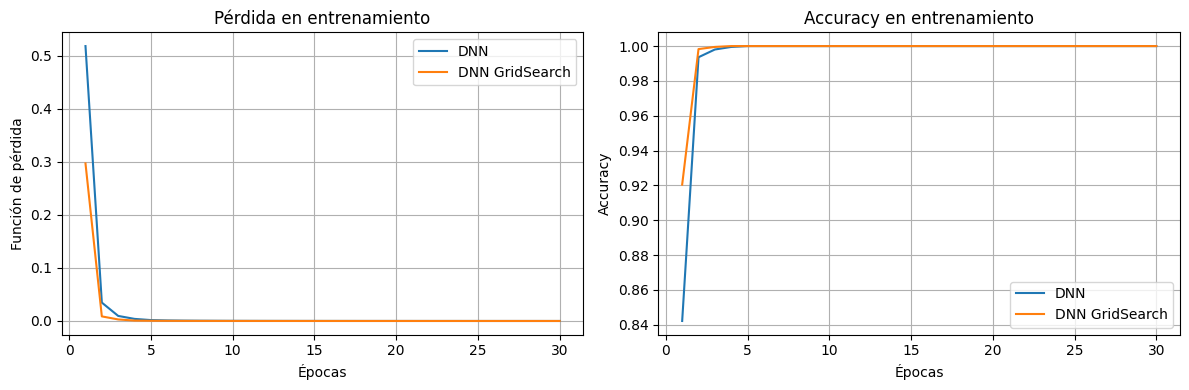

DNN - pérdida en la última época: 1.7e-05
DNN GridSearch - pérdida en la última época: 5e-06
DNN GridSearch - accuracy en la última época: 1.0


In [189]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, 31), dnn_base.history_["loss"], label="DNN")
axes[0].plot(range(1, 31), dnn_grid.history_["loss"], label="DNN GridSearch")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Función de pérdida")
axes[0].set_title("Pérdida en entrenamiento")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(range(1, 31), dnn_base.history_["accuracy"], label="DNN")
axes[1].plot(range(1, 31), dnn_grid.history_["accuracy"], label="DNN GridSearch")
axes[1].set_xlabel("Épocas")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy en entrenamiento")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("DNN - pérdida en la última época:", round(dnn_base.history_["loss"][-1], 6))
print("DNN GridSearch - pérdida en la última época:", round(dnn_grid.history_["loss"][-1], 6))
print("DNN GridSearch - accuracy en la última época:", round(dnn_grid.history_["accuracy"][-1], 4))

Las curvas del modelo ajustado son distintas a las del base: su pérdida no llega a cero, sino que sube y baja de una época a otra y termina en 0,0232, y su accuracy durante el entrenamiento se mantiene un poco por debajo de 100 % (99,70 % en la última época). Este comportamiento corresponde con su configuración: el dropout apaga el 20 % de las neuronas de cada capa oculta en cada paso del entrenamiento, y la tasa de aprendizaje es 10 veces mayor, por lo que cada cambio de los pesos es más grande.

#### Evaluación del modelo ajustado

Modelo: DNN GridSearch
Accuracy : 1.0000

Reporte de clasificación para: - Entrenamiento
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       810
           E     1.0000    1.0000    1.0000       810
           I     1.0000    1.0000    1.0000       810
           O     1.0000    1.0000    1.0000       820
           U     1.0000    1.0000    1.0000       810

    accuracy                         1.0000      4060
   macro avg     1.0000    1.0000    1.0000      4060
weighted avg     1.0000    1.0000    1.0000      4060



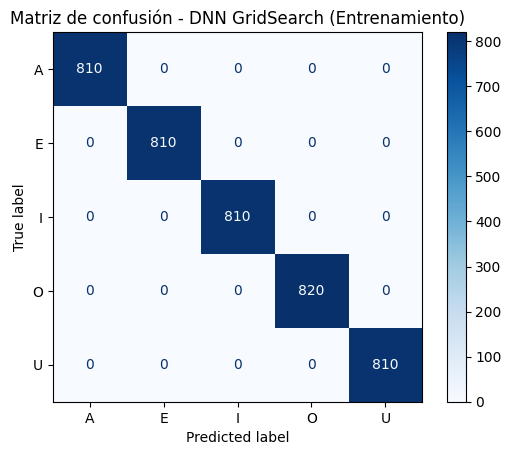

Modelo: DNN GridSearch
Accuracy : 0.9871

Reporte de clasificación para: - Prueba
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       200
           E     1.0000    0.9500    0.9744       200
           I     0.9434    1.0000    0.9709       200
           O     1.0000    0.9857    0.9928       210
           U     0.9950    1.0000    0.9975       200

    accuracy                         0.9871      1010
   macro avg     0.9877    0.9871    0.9871      1010
weighted avg     0.9878    0.9871    0.9872      1010



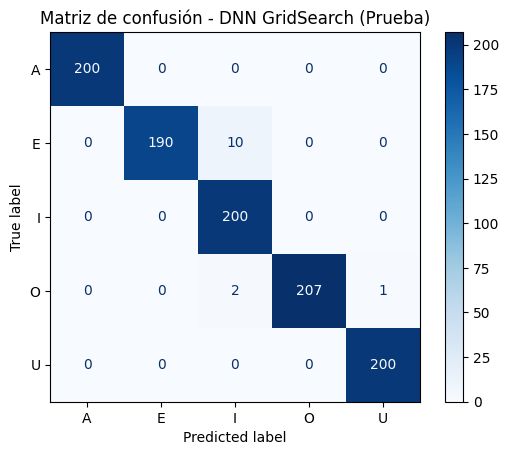

In [223]:
dnn_grid_pred_train = dnn_grid.predict(X_train_pca)
dnn_grid_pred_test = dnn_grid.predict(X_test_pca)

evaluar_modelo("DNN GridSearch", "Entrenamiento", y_train, dnn_grid_pred_train)
evaluar_modelo("DNN GridSearch", "Prueba", y_test, dnn_grid_pred_test)

In [224]:
comparacion_dnn = pd.DataFrame({"Modelo": ["DNN", "DNN GridSearch"],
                                "Accuracy entrenamiento": [accuracy_score(y_train, dnn_base_pred_train),
                                                           accuracy_score(y_train, dnn_grid_pred_train)],
                                "Accuracy validación": [val_dnn_base.mean(), grid_dnn.best_score_],
                                "Accuracy prueba": [accuracy_score(y_test, dnn_base_pred_test),
                                                    accuracy_score(y_test, dnn_grid_pred_test)]})
display(comparacion_dnn.round(4))

,Modelo,Accuracy entrenamiento,Accuracy validación,Accuracy prueba
0,DNN,1.0,0.9845,0.9891
1,DNN GridSearch,1.0,0.9864,0.9871


Al momento de predecir el dropout no se aplica y la red usa todas sus neuronas; por eso el modelo ajustado clasifica bien el 100 % de las imágenes de entrenamiento, aunque durante el entrenamiento su accuracy quedaba en 99,70 %.

En prueba el modelo ajustado obtiene el mismo resultado que el base: 98,91 %, con 11 errores. La matriz de confusión cambia en una sola imagen: 9 imágenes de la E clasificadas como I y 1 como U (en el base eran 10 como I), más la imagen de la O clasificada como U. El ajuste de hiperparámetros mejoró la validación en 0,27 puntos (de 98,45 % a 98,72 %) y la hizo más estable, pero no cambió el accuracy en el conjunto de prueba.

### 4.7 Comparación de los modelos

En esta sección se reúnen los resultados de todos los modelos entrenados: los seis modelos de regresión Softmax y, para el árbol de decisión, Random Forest, el MLP y la DNN, el modelo base y el modelo ajustado con `GridSearchCV`.

La comparación se hace en dos partes. Primero se comparan las métricas en los conjuntos de entrenamiento y prueba. Después se utilizan los resultados de la validación cruzada para ver el efecto que tuvo el ajuste de hiperparámetros en cada método.

#### Entrenamiento y prueba

Para cada modelo la tabla muestra el accuracy en entrenamiento y en prueba, la precision, el recall y el F1-score en prueba (calculados como el promedio de las cinco vocales), la cantidad de imágenes de prueba mal clasificadas y la diferencia entre el accuracy de entrenamiento y el de prueba.

In [221]:
predicciones = {"Regresión Softmax": (reg_sin_pred_train, reg_sin_pred_test),
                "Regresión Softmax L2 (Ridge)": (reg_ridge_pred_train, reg_ridge_pred_test),
                "Regresión Softmax L1 (Lasso)": (reg_lasso_pred_train, reg_lasso_pred_test),
                "Regresión Softmax GridSearch": (reg_sin_grid_pred_train, reg_sin_grid_pred_test),
                "Regresión Softmax con regularización GridSearch": (reg_grid_pred_train, reg_grid_pred_test),
                "Regresión Softmax con regularización GridSearch 2": (reg_grid2_pred_train, reg_grid2_pred_test),
                "Árbol de decisión": (arbol_base_pred_train, arbol_base_pred_test),
                "Árbol de decisión GridSearch": (arbol_grid_pred_train, arbol_grid_pred_test),
                "Random Forest": (bosque_base_pred_train, bosque_base_pred_test),
                "Random Forest GridSearch": (bosque_grid_pred_train, bosque_grid_pred_test),
                "MLP": (mlp_base_pred_train, mlp_base_pred_test),
                "MLP GridSearch": (mlp_grid_pred_train, mlp_grid_pred_test),
                "DNN": (dnn_base_pred_train, dnn_base_pred_test),
                "DNN GridSearch": (dnn_grid_pred_train, dnn_grid_pred_test)}

filas = []
for nombre, (pred_train, pred_test) in predicciones.items():
    filas.append({"Modelo": nombre,
                  "Accuracy entrenamiento": accuracy_score(y_train, pred_train),
                  "Accuracy prueba": accuracy_score(y_test, pred_test),
                  "Precision prueba": precision_score(y_test, pred_test, average="macro"),
                  "Recall prueba": recall_score(y_test, pred_test, average="macro"),
                  "F1-score prueba": f1_score(y_test, pred_test, average="macro"),
                  "Errores en prueba": (y_test != pred_test).sum()})

comparacion_final = pd.DataFrame(filas)
comparacion_final["Diferencia train - test"] = (comparacion_final["Accuracy entrenamiento"]
                                                - comparacion_final["Accuracy prueba"])
display(comparacion_final.round(4))

,Modelo,Accuracy entrenamiento,Accuracy prueba,Precision prueba,Recall prueba,F1-score prueba,Errores en prueba,Diferencia train - test
0,Regresión Softmax,1.0000,0.9782,0.9794,0.9782,0.9784,22,0.0218
1,Regresión Softmax L2 (Ridge),0.9995,0.9832,0.9841,0.9832,0.9833,17,0.0163
2,Regresión Softmax L1 (Lasso),0.9901,0.9723,0.9743,0.9723,0.9725,28,0.0179
3,Regresión Softmax GridSearch,1.0000,0.9792,0.9803,0.9792,0.9793,21,0.0208
4,Regresión Softmax con regularización GridSearch,0.9995,0.9812,0.9823,0.9812,0.9813,19,0.0183
5,Regresión Softmax con regularización GridSearch 2,1.0000,0.9812,0.9822,0.9812,0.9813,19,0.0188
6,Árbol de decisión,1.0000,0.9218,0.9229,0.9221,0.9223,79,0.0782
7,Árbol de decisión GridSearch,0.9805,0.8851,0.8882,0.8851,0.8858,116,0.0954
8,Random Forest,1.0000,0.9842,0.9844,0.9846,0.9842,16,0.0158
9,Random Forest GridSearch,1.0000,0.9901,0.9903,0.9904,0.9902,10,0.0099


#### Efecto del ajuste de hiperparámetros en la validación cruzada

La comparación anterior usa un solo conjunto de prueba. La validación cruzada permite comparar el modelo base y el modelo ajustado de cada método con cinco evaluaciones distintas: la media indica el desempeño promedio y la desviación estándar indica cuánto cambia ese desempeño de una parte de validación a otra.

Para la regresión Softmax, el modelo base es el modelo sin regularización con el valor de `tol` por defecto, y el modelo ajustado es el seleccionado en la segunda búsqueda con regularización.

In [222]:
indice_base_reg = grid_reg_sin.cv_results_["params"].index({"tol": 1e-4})

comparacion_validacion = pd.DataFrame({
    "Método": ["Regresión Softmax", "Árbol de decisión", "Random Forest", "MLP", "DNN"],
    "Media base": [grid_reg_sin.cv_results_["mean_test_score"][indice_base_reg], val_arbol_base.mean(),
                   val_bosque_base.mean(), val_mlp_base.mean(), val_dnn_base.mean()],
    "Desviación base": [grid_reg_sin.cv_results_["std_test_score"][indice_base_reg], val_arbol_base.std(),
                        val_bosque_base.std(), val_mlp_base.std(), val_dnn_base.std()],
    "Media GridSearch": [grid_reg2.best_score_, grid_arbol.best_score_, grid_bosque.best_score_,
                         grid_mlp.best_score_, grid_dnn.best_score_],
    "Desviación GridSearch": [grid_reg2.cv_results_["std_test_score"][grid_reg2.best_index_],
                              grid_arbol.cv_results_["std_test_score"][grid_arbol.best_index_],
                              grid_bosque.cv_results_["std_test_score"][grid_bosque.best_index_],
                              grid_mlp.cv_results_["std_test_score"][grid_mlp.best_index_],
                              grid_dnn.cv_results_["std_test_score"][grid_dnn.best_index_]]})

comparacion_validacion["Diferencia"] = (comparacion_validacion["Media GridSearch"]
                                        - comparacion_validacion["Media base"])
display(comparacion_validacion.round(4))

,Método,Media base,Desviación base,Media GridSearch,Desviación GridSearch,Diferencia
0,Regresión Softmax,0.9665,0.0191,0.9702,0.0153,0.0037
1,Árbol de decisión,0.8650,0.0285,0.8793,0.0125,0.0144
2,Random Forest,0.9785,0.0100,0.9835,0.0074,0.0049
3,MLP,0.9832,0.0134,0.9857,0.0117,0.0025
4,DNN,0.9845,0.0128,0.9864,0.0130,0.0020
